# Housing Loan Prediction — Exploration & Preprocessing

**Données** : HMDA (Home Mortgage Disclosure Act), demandes de prêt immobilier aux États-Unis.  
**Tâche** : classification binaire, `accepted = 1` (accordé) vs `0` (refusé). Cible déséquilibrée.

## Trame du notebook

| # | Étape | Points clés |
|---|---|---|
| 1 | **Chargement & vue d'ensemble** | dimensions, types, cohérence train/test, doublons, distribution de la cible |
| 2 | **Typologie des variables** | séparer continues / codes catégoriels / tranches ordinales / géographiques / quartier (tract) ; dictionnaire des codes HMDA |
| 3 | **Valeurs manquantes** | NaN explicites **et** manquants déguisés (`1111` = Exempt, `99999`, `0`, `-1`, « Not Available ») ; co-manquance ; lien entre manquant et cible |
| 4 | **Variables numériques & outliers** | distributions, valeurs aberrantes (LTV, montants, revenu négatif), cohérence `LTV ≈ loan / property_value`, transformation log, winsorisation |
| 5 | **Variables catégorielles** | cardinalité, modalités rares, taux d'acceptation par modalité, `debt_to_income_ratio` (format mixte) et âges (tranches) à rendre ordinales |
| 6 | **Lien avec la cible & redondance** | variables les plus discriminantes, corrélations, colonnes redondantes (`derived_*` vs colonnes brutes) |
| 7 | **Train vs test** | non réalisée à part : train et test restent quasi identiques à chaque étape |
| 8 | **Pipeline de preprocessing** | traduire les décisions en fonctions réutilisables, ajustées sur le train uniquement (pas de fuite), export des jeux propres |

**Points de vigilance transverses**
- Déséquilibre 85/15 : l'accuracy n'est pas informative, stratifier toutes les validations.
- `sample_submission.csv` contient des **probabilités** : la métrique est probablement de type AUC / log-loss (à confirmer dans l'énoncé).
- Variables de profil (ethnie, race, sexe, âge) : à décider si on les utilise, et à documenter.
- Toute statistique de preprocessing (médiane, bornes, encodage) se calcule sur le train seul.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Le notebook peut être lancé depuis la racine du projet ou depuis notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"

TARGET = "accepted"
ID_COL = "id"
SEED = 42

In [2]:
# Style graphique commun à tout le notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "legend.frameon": False, "legend.fontsize": 9,
})

## 1. Chargement et vue d'ensemble

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv", low_memory=False)
test = pd.read_csv(DATA_DIR / "test.csv", low_memory=False)
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

print(f"train : {train.shape[0]:,} lignes x {train.shape[1]} colonnes")
print(f"test  : {test.shape[0]:,} lignes x {test.shape[1]} colonnes")
print(f"Colonnes présentes dans un seul des deux fichiers : {set(train.columns) ^ set(test.columns)}")
print(f"Même ordre de colonnes (hors cible) : {list(train.columns.drop(TARGET)) == list(test.columns)}")

train : 105,000 lignes x 58 colonnes
test  : 45,000 lignes x 57 colonnes
Colonnes présentes dans un seul des deux fichiers : {'accepted'}
Même ordre de colonnes (hors cible) : True


In [4]:
# Aperçu transposé : une ligne par variable, plus lisible avec 58 colonnes
train.head(5).T

,0,1,2,3,4
id,544438,316090,153632,400700,205569
loan_amount,"705,000.00","295,000.00","305,000.00","765,000.00","1,775,000.00"
loan_to_value_ratio,46.82,53.00,80.00,58.97,60.00
property_value,"1,495,000.00","555,000.00","385,000.00","1,305,000.00","2,955,000.00"
income,655.00,63.00,109.00,190.00,"15,675.00"
loan_term,360.00,360.00,360.00,360.00,360.00
total_units,1.00,1.00,1.00,1.00,1.00
state_code,CA,NC,VA,NC,FL
derived_msa-md,34900,99999,40060,16740,33124
county_code,"6,055.00","37,113.00","51,087.00","37,179.00","12,086.00"


### 1.1 Résumé par variable
Type, nombre de valeurs distinctes et taux de NaN (train et test).

In [5]:
summary = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_unique": train.nunique(),
    "na_train_%": train.isna().mean() * 100,
    "na_test_%": (test.isna().mean() * 100).reindex(train.columns),
    "exemple": train.iloc[0].astype(str),
})

print(summary["dtype"].value_counts().to_string())
summary

dtype
int64      36
float64    12
str        10


,dtype,n_unique,na_train_%,na_test_%,exemple
id,int64,105000,0.00,0.00,544438
loan_amount,float64,465,0.00,0.00,705000.0
loan_to_value_ratio,float64,18013,11.31,11.29,46.823
property_value,float64,580,4.53,4.42,1495000.0
income,float64,1538,4.36,4.49,655.0
loan_term,float64,227,3.15,3.10,360.0
total_units,float64,4,0.42,0.38,1.0
state_code,str,54,0.78,0.82,CA
derived_msa-md,int64,418,0.00,0.00,34900
county_code,float64,2898,1.28,1.32,6055.0


### 1.2 Identifiants et doublons

In [6]:
features = [c for c in train.columns if c not in (ID_COL, TARGET)]

print(f"id dupliqués dans train            : {train[ID_COL].duplicated().sum()}")
print(f"id dupliqués dans test             : {test[ID_COL].duplicated().sum()}")
print(f"id communs train/test              : {len(set(train[ID_COL]) & set(test[ID_COL]))}")
print(f"id du test == id de la soumission  : {(test[ID_COL] == sample_sub[ID_COL]).all()}")
print(f"lignes dupliquées (features+cible) : {train.duplicated(subset=features + [TARGET]).sum()}")
print(f"lignes dupliquées (features seules): {train.duplicated(subset=features).sum()}")

id dupliqués dans train            : 0
id dupliqués dans test             : 0
id communs train/test              : 0
id du test == id de la soumission  : True


lignes dupliquées (features+cible) : 7
lignes dupliquées (features seules): 7


### 1.3 Distribution de la cible

In [7]:
target_dist = pd.DataFrame({
    "n": train[TARGET].value_counts(),
    "%": train[TARGET].value_counts(normalize=True) * 100,
}).rename(index={1: "1 (accordé)", 0: "0 (refusé)"})
display(target_dist)

print(f"Valeurs manquantes dans la cible : {train[TARGET].isna().sum()}")
print(f"Valeur constante de sample_submission : {sample_sub[TARGET].unique()}")

,n,%
accepted,,
1 (accordé),89244,84.99
0 (refusé),15756,15.01


Valeurs manquantes dans la cible : 0
Valeur constante de sample_submission : [0.8499]


## 2. Typologie des variables

Le type pandas ne dit pas la nature d'une variable : sur les 36 colonnes entières, la plupart sont des **codes** (`loan_type = 1, 2, 3, 4`) sans ordre ni distance. On classe donc chaque variable à la main selon sa nature statistique, car c'est elle qui détermine le traitement (outliers et échelle pour les continues, encodage pour les catégorielles).

### 2.1 Groupes de variables

In [8]:
VAR_GROUPS = {
    # Quantités mesurées sur le dossier (income en milliers de $, loan_term en mois)
    "num_dossier": [
        "loan_amount", "loan_to_value_ratio", "property_value", "income", "loan_term", "total_units",
    ],
    # Quantités décrivant le quartier (census tract) du bien
    "num_quartier": [
        "tract_population", "tract_minority_population_percent", "ffiec_msa_md_median_family_income",
        "tract_to_msa_income_percentage", "tract_owner_occupied_units", "tract_one_to_four_family_homes",
        "tract_median_age_of_housing_units",
    ],
    # Identifiants géographiques : des nombres, mais purement nominaux et à forte cardinalité
    "geo": ["state_code", "derived_msa-md", "county_code"],
    # Tranches stockées en texte, avec un ordre naturel
    "ord_tranches": ["debt_to_income_ratio", "applicant_age", "co-applicant_age"],
    # Caractéristiques du prêt
    "cat_pret": [
        "derived_loan_product_type", "loan_type", "lien_status", "conforming_loan_limit", "preapproval",
        "reverse_mortgage", "open-end_line_of_credit", "business_or_commercial_purpose",
        "negative_amortization", "interest_only_payment", "balloon_payment", "other_nonamortizing_features",
    ],
    # Caractéristiques du bien financé
    "cat_bien": [
        "derived_dwelling_category", "construction_method", "occupancy_type",
        "manufactured_home_secured_property_type", "manufactured_home_land_property_interest",
    ],
    # Façon dont le dossier a été déposé et instruit
    "cat_instruction": [
        "applicant_credit_score_type", "co-applicant_credit_score_type", "submission_of_application",
        "initially_payable_to_institution", "aus-1",
    ],
    # Profil déclaratif de l'emprunteur et du co-emprunteur
    "cat_profil": [
        "derived_ethnicity", "derived_race", "derived_sex",
        "applicant_ethnicity-1", "co-applicant_ethnicity-1",
        "applicant_ethnicity_observed", "co-applicant_ethnicity_observed",
        "applicant_race-1", "co-applicant_race-1",
        "applicant_race_observed", "co-applicant_race_observed",
        "applicant_sex", "co-applicant_sex",
        "applicant_sex_observed", "co-applicant_sex_observed",
    ],
}

# Chaque variable explicative doit appartenir à un groupe et un seul
assigned = [c for cols in VAR_GROUPS.values() for c in cols]
assert len(assigned) == len(set(assigned)), "variable présente dans deux groupes"
assert set(assigned) == set(features), set(assigned) ^ set(features)

NUM_COLS = VAR_GROUPS["num_dossier"] + VAR_GROUPS["num_quartier"]
CAT_COLS = [c for g, cols in VAR_GROUPS.items() if g.startswith("cat_") for c in cols]

pd.DataFrame({
    "n_variables": {g: len(cols) for g, cols in VAR_GROUPS.items()},
    "n_unique (min - max)": {
        g: f"{train[cols].nunique().min()} - {train[cols].nunique().max()}" for g, cols in VAR_GROUPS.items()
    },
    "dtypes": {
        g: ", ".join(sorted(set(train[cols].dtypes.astype(str)))) for g, cols in VAR_GROUPS.items()
    },
})

,n_variables,n_unique (min - max),dtypes
num_dossier,6,4 - 18013,float64
num_quartier,7,77 - 9426,"float64, int64"
geo,3,54 - 2898,"float64, int64, str"
ord_tranches,3,7 - 19,str
cat_pret,12,2 - 7,"int64, str"
cat_bien,5,2 - 6,"int64, str"
cat_instruction,5,3 - 16,int64
cat_profil,15,3 - 19,"float64, int64, str"


### 2.2 Dictionnaire des codes HMDA

Libellés issus de la documentation officielle des champs HMDA (FFIEC, *Public HMDA – LAR Data Fields*). Trois familles de codes spéciaux reviennent et seront traitées à l'étape 3 :
- `1111` = **Exempt** : l'établissement est dispensé de déclarer ce champ ;
- « Not applicable » / « Information not provided » : la question ne s'applique pas ou n'a pas reçu de réponse ;
- « No co-applicant » : il n'y a pas de co-emprunteur (ce n'est pas une donnée manquante, c'est une information).

In [9]:
EXEMPT = {1111: "Exempt"}
YES_NO = {1: "Oui", 2: "Non", **EXEMPT}

CREDIT_SCORE = {
    1: "Equifax Beacon 5.0", 2: "Experian Fair Isaac", 3: "FICO Risk Score Classic 04",
    4: "FICO Risk Score Classic 98", 5: "VantageScore 2.0", 6: "VantageScore 3.0",
    7: "More than one credit scoring model", 8: "Other credit scoring model", 9: "Not applicable",
    11: "FICO Score 9", 12: "FICO Score 8", 13: "FICO Score 10", 14: "FICO Score 10T",
    15: "VantageScore 4.0", **EXEMPT,
}
ETHNICITY = {
    1: "Hispanic or Latino", 11: "Mexican", 12: "Puerto Rican", 13: "Cuban",
    14: "Other Hispanic or Latino", 2: "Not Hispanic or Latino",
    3: "Information not provided", 4: "Not applicable",
}
RACE = {
    1: "American Indian or Alaska Native", 2: "Asian", 21: "Asian Indian", 22: "Chinese",
    23: "Filipino", 24: "Japanese", 25: "Korean", 26: "Vietnamese", 27: "Other Asian",
    3: "Black or African American", 4: "Native Hawaiian or Other Pacific Islander",
    41: "Native Hawaiian", 42: "Guamanian or Chamorro", 43: "Samoan", 44: "Other Pacific Islander",
    5: "White", 6: "Information not provided", 7: "Not applicable",
}
SEX = {
    1: "Male", 2: "Female", 3: "Information not provided", 4: "Not applicable",
    6: "Applicant selected both male and female",
}
OBSERVED = {
    1: "Collected on the basis of visual observation or surname",
    2: "Not collected on the basis of visual observation or surname",
    3: "Not applicable",
}

HMDA_CODES = {
    # Prêt
    "loan_type": {1: "Conventional", 2: "FHA", 3: "VA", 4: "USDA / RHS / FSA"},
    "lien_status": {1: "First lien", 2: "Subordinate lien"},
    "conforming_loan_limit": {"C": "Conforming", "NC": "Nonconforming", "U": "Undetermined"},
    "preapproval": {1: "Preapproval requested", 2: "Preapproval not requested"},
    "reverse_mortgage": YES_NO,
    "open-end_line_of_credit": YES_NO,
    "business_or_commercial_purpose": YES_NO,
    "negative_amortization": YES_NO,
    "interest_only_payment": YES_NO,
    "balloon_payment": YES_NO,
    "other_nonamortizing_features": YES_NO,
    # Bien
    "construction_method": {1: "Site-built", 2: "Manufactured home"},
    "occupancy_type": {1: "Principal residence", 2: "Second residence", 3: "Investment property"},
    "manufactured_home_secured_property_type": {
        1: "Manufactured home and land", 2: "Manufactured home and not land", 3: "Not applicable", **EXEMPT,
    },
    "manufactured_home_land_property_interest": {
        1: "Direct ownership", 2: "Indirect ownership", 3: "Paid leasehold", 4: "Unpaid leasehold",
        5: "Not applicable", **EXEMPT,
    },
    # Instruction du dossier
    "applicant_credit_score_type": CREDIT_SCORE,
    "co-applicant_credit_score_type": {**CREDIT_SCORE, 10: "No co-applicant"},
    "submission_of_application": {
        1: "Submitted directly to the institution", 2: "Not submitted directly", 3: "Not applicable", **EXEMPT,
    },
    "initially_payable_to_institution": {
        1: "Initially payable to the institution", 2: "Not initially payable", 3: "Not applicable", **EXEMPT,
    },
    "aus-1": {
        1: "Desktop Underwriter (DU)", 2: "Loan Prospector / Loan Product Advisor (LP)",
        3: "TOTAL Scorecard", 4: "Guaranteed Underwriting System (GUS)", 5: "Other",
        6: "Not applicable", 7: "Internal proprietary system", **EXEMPT,
    },
    # Profil
    "applicant_ethnicity-1": ETHNICITY,
    "co-applicant_ethnicity-1": {**ETHNICITY, 5: "No co-applicant"},
    "applicant_ethnicity_observed": OBSERVED,
    "co-applicant_ethnicity_observed": {**OBSERVED, 4: "No co-applicant"},
    "applicant_race-1": RACE,
    "co-applicant_race-1": {**RACE, 8: "No co-applicant"},
    "applicant_race_observed": OBSERVED,
    "co-applicant_race_observed": {**OBSERVED, 4: "No co-applicant"},
    "applicant_sex": SEX,
    "co-applicant_sex": {**SEX, 5: "No co-applicant"},
    "applicant_sex_observed": OBSERVED,
    "co-applicant_sex_observed": {**OBSERVED, 4: "No co-applicant"},
}

# Contrôle : toute valeur observée (train + test) doit avoir un libellé
unknown = {
    col: sorted(set(pd.concat([train[col], test[col]]).dropna().unique()) - set(codes))
    for col, codes in HMDA_CODES.items()
}
unknown = {col: vals for col, vals in unknown.items() if vals}
print(f"{len(HMDA_CODES)} variables codées documentées")
print(f"Codes observés sans libellé : {unknown if unknown else 'aucun'}")
print(f"Catégorielles sans dictionnaire (libellés déjà en clair) : {sorted(set(CAT_COLS) - set(HMDA_CODES))}")

32 variables codées documentées
Codes observés sans libellé : aucun
Catégorielles sans dictionnaire (libellés déjà en clair) : ['derived_dwelling_category', 'derived_ethnicity', 'derived_loan_product_type', 'derived_race', 'derived_sex']


In [10]:
def decode(df, col):
    """Remplace les codes HMDA d'une colonne par leur libellé (les NaN restent NaN)."""
    return df[col].map(HMDA_CODES[col]) if col in HMDA_CODES else df[col]


# Codebook : effectif de chaque modalité dans le train, avec son libellé
rows = []
for col, codes in HMDA_CODES.items():
    for value, n in train[col].value_counts(dropna=False).items():
        rows.append({
            "variable": col,
            "code": "NaN" if pd.isna(value) else str(int(value)) if isinstance(value, (int, float)) else value,
            "libellé": codes.get(value, "(manquant)"),
            "n": n,
            "%": n / len(train) * 100,
        })
codebook = pd.DataFrame(rows).set_index(["variable", "code"])

with pd.option_context("display.max_rows", None):
    display(codebook)

libellé  \
variable                                 code                                                      
loan_type                                1                                          Conventional   
                                         2                                                   FHA   
                                         3                                                    VA   
                                         4                                      USDA / RHS / FSA   
lien_status                              1                                            First lien   
                                         2                                      Subordinate lien   
conforming_loan_limit                    C                                            Conforming   
                                         NC                                        Nonconforming   
                                         NaN                                          (manquant)   
                                         U                                          Undetermined   
preapproval                              2                             Preapproval not requested   
                                         1                                 Preapproval requested   
reverse_mortgage                         2                                                   Non   
                                         1111                                             Exempt   
                                         1                                                   Oui   
open-end_line_of_credit                  2                                                   Non   
                                         1111                                             Exempt   
                                         1                                                   Oui   
business_or_commercial_purpose           2                                                   Non   
                                         1                                                   Oui   
                                         1111                                             Exempt   
negative_amortization                    2                                                   Non   
                                         1111                                             Exempt   
                                         1                                                   Oui   
interest_only_payment                    2                                                   Non   
                                         1                                                   Oui   
                                         1111                                             Exempt   
balloon_payment                          2                                                   Non   
                                         1                                                   Oui   
                                         1111                                             Exempt   
other_nonamortizing_features             2                                                   Non   
                                         1111                                             Exempt   
                                         1                                                   Oui   
construction_method                      1                                            Site-built   
                                         2                                     Manufactured home   
occupancy_type                           1                                   Principal residence   
                                         3                                   Investment property   
                                         2                                      Second residence   
manufactured_home_secured_property_type  3                                        Not app

### 2.3 À retenir

- **56 variables explicatives** : 13 numériques (6 dossier + 7 quartier), 3 géographiques, 3 ordinales en tranches, 37 catégorielles.
- **Seules 13 variables sont de vraies quantités.** Parmi les autres colonnes stockées en nombres, 31 sont des codes catégoriels et 2 des identifiants géographiques : les passer telles quelles à un modèle linéaire lui ferait croire que `loan_type = 4` vaut « deux fois » `loan_type = 2`.
- **`1111` est toujours « Exempt »** dans les variables codées : jamais une valeur numérique à interpréter.
- **Co-emprunteur** : environ 55 % des dossiers n'en ont pas. L'information est portée par un code dédié dans chaque variable `co-applicant_*` (5, 8, 4 ou 10 selon la colonne), sauf `co-applicant_age` où elle apparaît en NaN.
- **Variables géographiques** : jusqu'à 2 898 modalités (`county_code`), un one-hot n'est pas envisageable.
- **Redondances probables** à vérifier à l'étape 6 : `derived_loan_product_type` = `loan_type` × `lien_status` ; `derived_dwelling_category` recoupe `construction_method` ; `derived_ethnicity / race / sex` sont calculées à partir des colonnes `applicant_*` et `co-applicant_*`.

## 3. Valeurs manquantes

Trois questions, dans l'ordre :
1. **Où** sont les manquants, y compris ceux qui ne sont pas des NaN (codes `1111`, `0`, « Not Available ») ?
2. **Comment** sont-ils structurés : au hasard, ou par blocs de lignes qui s'expliquent ?
3. **Sont-ils liés à la cible ?** Si oui, le fait d'être manquant est lui-même une information, et il ne faut ni supprimer les lignes ni imputer à l'aveugle.

### 3.1 NaN explicites

,n_train,na_train_%,na_test_%
co-applicant_age,58693,55.90,55.84
loan_to_value_ratio,11874,11.31,11.29
debt_to_income_ratio,7679,7.31,7.37
property_value,4756,4.53,4.42
income,4578,4.36,4.49
loan_term,3307,3.15,3.10
applicant_age,3088,2.94,3.01
county_code,1339,1.28,1.32
state_code,824,0.78,0.82
total_units,437,0.42,0.38


15 variables sur 56 contiennent des NaN
Lignes avec au moins un NaN : 61.3% (16.5% sans compter co-applicant_age)


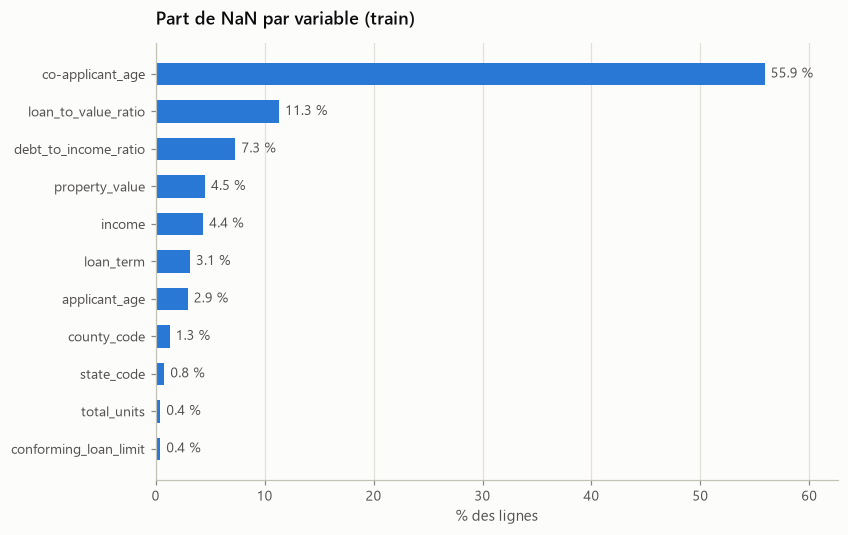

In [11]:
na = pd.DataFrame({
    "n_train": train[features].isna().sum(),
    "na_train_%": train[features].isna().mean() * 100,
    "na_test_%": test[features].isna().mean() * 100,
})
na = na[na["n_train"] > 0].sort_values("na_train_%", ascending=False)
display(na)

any_na = train[features].isna().any(axis=1).mean()
any_na_hors_coapp = train[features].drop(columns="co-applicant_age").isna().any(axis=1).mean()
print(f"{len(na)} variables sur {len(features)} contiennent des NaN")
print(f"Lignes avec au moins un NaN : {any_na:.1%} ({any_na_hors_coapp:.1%} sans compter co-applicant_age)")

# Graphique : on laisse de côté les variables à moins de 0,1 % de NaN
plot = na.loc[na["na_train_%"] >= 0.1, "na_train_%"].sort_values()
fig, ax = plt.subplots(figsize=(8, 0.36 * len(plot) + 1.2))
bars = ax.barh(plot.index, plot, height=0.6, color=PALETTE[0])
ax.bar_label(bars, fmt="%.1f %%", padding=4, color=INK_2, fontsize=9)
ax.set(title="Part de NaN par variable (train)", xlabel="% des lignes", xlim=(0, plot.max() * 1.12))
ax.grid(axis="y", visible=False)
plt.show()

### 3.2 Manquants déguisés

Beaucoup de « trous » ne sont pas des NaN mais des codes. On les range en trois types, car ils n'appellent pas le même traitement :

| Type | Sens | Exemple | La valeur existe-t-elle ? |
|---|---|---|---|
| `exempt` | l'établissement est dispensé de déclarer le champ | `1111` | oui, mais on ne la connaît pas |
| `non_renseigne` | l'information n'a pas été fournie | race = 6, « Race Not Available », quartier à 0 habitant | oui, mais on ne la connaît pas |
| `sans_objet` | la question ne se pose pas | pas de co-emprunteur, bien non préfabriqué | non : c'est une **information**, pas un trou |

In [12]:
EXEMPT_COLS = [col for col, codes in HMDA_CODES.items() if 1111 in codes]
TRACT_COLS = VAR_GROUPS["num_quartier"]
OBSERVED_COLS = [c for c in features if c.endswith("_observed")]

# (colonnes concernées, valeur spéciale, type)
SPECIAL_RULES = [
    (EXEMPT_COLS, 1111, "exempt"),
    # Profil : "Information not provided" vs "Not applicable" vs "No co-applicant"
    (["applicant_ethnicity-1", "co-applicant_ethnicity-1"], 3, "non_renseigne"),
    (["applicant_ethnicity-1", "co-applicant_ethnicity-1"], 4, "sans_objet"),
    (["co-applicant_ethnicity-1"], 5, "sans_objet"),
    (["applicant_race-1", "co-applicant_race-1"], 6, "non_renseigne"),
    (["applicant_race-1", "co-applicant_race-1"], 7, "sans_objet"),
    (["co-applicant_race-1"], 8, "sans_objet"),
    (["applicant_sex", "co-applicant_sex"], 3, "non_renseigne"),
    (["applicant_sex", "co-applicant_sex"], 4, "sans_objet"),
    (["co-applicant_sex"], 5, "sans_objet"),
    (OBSERVED_COLS, 3, "sans_objet"),
    ([c for c in OBSERVED_COLS if c.startswith("co-")], 4, "sans_objet"),
    (["derived_ethnicity"], "Ethnicity Not Available", "non_renseigne"),
    (["derived_race"], "Race Not Available", "non_renseigne"),
    (["derived_sex"], "Sex Not Available", "non_renseigne"),
    # Instruction du dossier
    (["applicant_credit_score_type", "co-applicant_credit_score_type"], 9, "sans_objet"),
    (["co-applicant_credit_score_type"], 10, "sans_objet"),
    (["aus-1"], 6, "sans_objet"),
    (["submission_of_application", "initially_payable_to_institution"], 3, "sans_objet"),
    # Bien et prêt
    (["manufactured_home_secured_property_type"], 3, "sans_objet"),
    (["manufactured_home_land_property_interest"], 5, "sans_objet"),
    (["conforming_loan_limit"], "U", "non_renseigne"),
    # Géographie : 99999 = hors zone métropolitaine (ou zone inconnue) ; 0 sur une variable de quartier = quartier inconnu
    (["derived_msa-md"], 99999, "sans_objet"),
    (TRACT_COLS, 0, "non_renseigne"),
]

profile = pd.DataFrame(0.0, index=features, columns=["nan", "exempt", "non_renseigne", "sans_objet"])
profile["nan"] = train[features].isna().mean() * 100
for cols, value, kind in SPECIAL_RULES:
    for col in cols:
        profile.loc[col, kind] += (train[col] == value).mean() * 100

UNKNOWN_KINDS = ["nan", "exempt", "non_renseigne"]
profile["inconnu_total"] = profile[UNKNOWN_KINDS].sum(axis=1)
profile = profile[profile.sum(axis=1) > 0].sort_values("inconnu_total", ascending=False)

print(f"Variables avec des NaN              : {(profile['nan'] > 0).sum()}")
print(f"Variables avec une valeur inconnue  : {(profile['inconnu_total'] > 0).sum()} (NaN, exempt ou non renseigné)")
print(f"Variables sans aucune valeur spéciale : {len(features) - len(profile)}")
with pd.option_context("display.max_rows", None):
    display(profile)

Variables avec des NaN              : 15
Variables avec une valeur inconnue  : 41 (NaN, exempt ou non renseigné)
Variables sans aucune valeur spéciale : 8


,nan,exempt,non_renseigne,sans_objet,inconnu_total
co-applicant_age,55.90,0.00,0.00,0.00,55.90
derived_race,0.00,0.00,17.02,0.00,17.02
derived_ethnicity,0.00,0.00,15.46,0.00,15.46
applicant_race-1,0.02,0.00,14.24,2.78,14.26
applicant_ethnicity-1,0.03,0.00,12.68,2.78,12.71
loan_to_value_ratio,11.31,0.00,0.00,0.00,11.31
derived_sex,0.00,0.00,7.90,0.00,7.90
debt_to_income_ratio,7.31,0.00,0.00,0.00,7.31
co-applicant_race-1,0.01,0.00,7.16,55.71,7.17
co-applicant_ethnicity-1,0.01,0.00,6.45,55.81,6.46


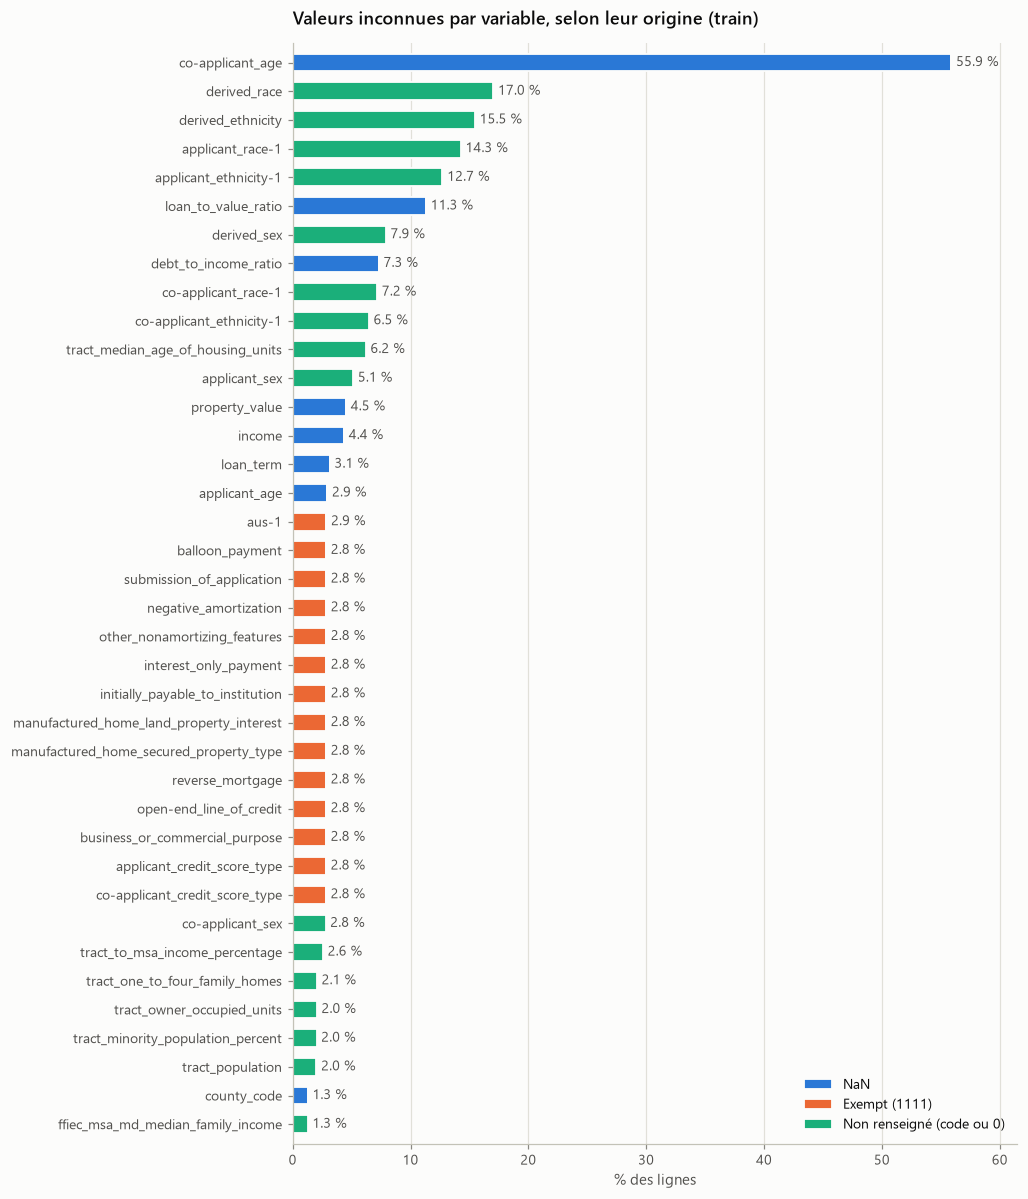

In [13]:
# Part de valeurs réellement inconnues par variable, décomposée par origine (seuil : 1 % des lignes)
plot = profile.loc[profile["inconnu_total"] >= 1, UNKNOWN_KINDS + ["inconnu_total"]].sort_values("inconnu_total")
labels = {"nan": "NaN", "exempt": "Exempt (1111)", "non_renseigne": "Non renseigné (code ou 0)"}

fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(plot) + 1.6))
left = np.zeros(len(plot))
for kind, color in zip(UNKNOWN_KINDS, PALETTE):
    ax.barh(plot.index, plot[kind], left=left, height=0.62, color=color, label=labels[kind],
            edgecolor=SURFACE, linewidth=1.2)
    left += plot[kind].to_numpy()
for y, total in enumerate(plot["inconnu_total"]):
    ax.text(total + 0.4, y, f"{total:.1f} %", va="center", fontsize=9, color=INK_2)

ax.set(title="Valeurs inconnues par variable, selon leur origine (train)", xlabel="% des lignes",
       xlim=(0, plot["inconnu_total"].max() * 1.1))
ax.margins(y=0.01)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
plt.show()

### 3.3 Structure des manquants

Les manquants tombent-ils au hasard, ou sur les mêmes lignes ? On construit un indicateur (vrai/faux) par type de manquant, plus quelques caractéristiques du dossier susceptibles de les expliquer, puis on regarde lesquels vont ensemble.

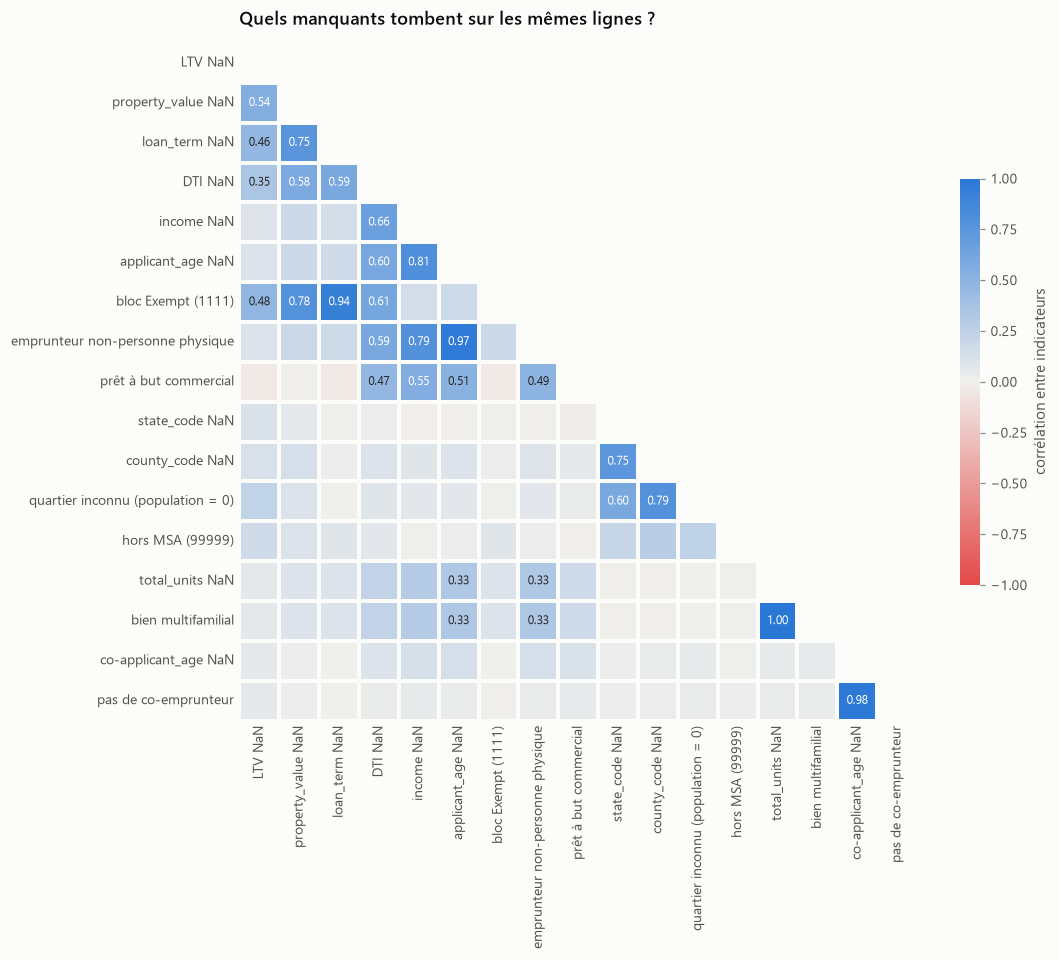

In [14]:
def missing_flags(df):
    """Indicateurs de manquants et de caractéristiques du dossier qui peuvent les expliquer."""
    return pd.DataFrame({
        # Manquants sur le dossier
        "LTV NaN": df["loan_to_value_ratio"].isna(),
        "property_value NaN": df["property_value"].isna(),
        "loan_term NaN": df["loan_term"].isna(),
        "DTI NaN": df["debt_to_income_ratio"].isna(),
        "income NaN": df["income"].isna(),
        "applicant_age NaN": df["applicant_age"].isna(),
        # Explications possibles
        "bloc Exempt (1111)": (df[EXEMPT_COLS] == 1111).any(axis=1),
        "emprunteur non-personne physique": df["applicant_sex"] == 4,
        "prêt à but commercial": df["business_or_commercial_purpose"] == 1,
        # Géographie
        "state_code NaN": df["state_code"].isna(),
        "county_code NaN": df["county_code"].isna(),
        "quartier inconnu (population = 0)": df["tract_population"] == 0,
        "hors MSA (99999)": df["derived_msa-md"] == 99999,
        # Manquants structurels
        "total_units NaN": df["total_units"].isna(),
        "bien multifamilial": df["derived_dwelling_category"].str.startswith("Multifamily"),
        "co-applicant_age NaN": df["co-applicant_age"].isna(),
        "pas de co-emprunteur": df["co-applicant_sex"] == 5,
    })


flags = missing_flags(train)
corr = flags.astype(int).corr()

# Triangle inférieur seulement ; on n'annote que les liens nets (|r| >= 0.3)
mask = np.triu(np.ones_like(corr, dtype=bool))
annot = corr.apply(lambda col: col.map("{:.2f}".format)).where(corr.abs() >= 0.3, "")
diverging = sns.blend_palette(["#e34948", "#f0efec", "#2a78d6"], as_cmap=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, cmap=diverging, vmin=-1, vmax=1, annot=annot, fmt="", annot_kws={"fontsize": 8},
            linewidths=1.5, linecolor=SURFACE, square=True, ax=ax,
            cbar_kws={"shrink": 0.6, "label": "corrélation entre indicateurs"})
ax.set_title("Quels manquants tombent sur les mêmes lignes ?")
ax.grid(False)
ax.tick_params(length=0)
plt.show()

In [15]:
# Recouvrement exact des paires qui ressortent : quelle part de A est aussi dans B, et inversement ?
PAIRS = [
    ("total_units NaN", "bien multifamilial"),
    ("co-applicant_age NaN", "pas de co-emprunteur"),
    ("applicant_age NaN", "emprunteur non-personne physique"),
    ("income NaN", "emprunteur non-personne physique"),
    ("bloc Exempt (1111)", "DTI NaN"),
    ("bloc Exempt (1111)", "LTV NaN"),
    ("bloc Exempt (1111)", "loan_term NaN"),
    ("prêt à but commercial", "DTI NaN"),
    ("county_code NaN", "quartier inconnu (population = 0)"),
    ("state_code NaN", "county_code NaN"),
]
overlap = pd.DataFrame([
    {
        "A": a, "B": b,
        "n A": flags[a].sum(), "n B": flags[b].sum(), "n A et B": (flags[a] & flags[b]).sum(),
        "% de A dans B": (flags[a] & flags[b]).sum() / flags[a].sum() * 100,
        "% de B dans A": (flags[a] & flags[b]).sum() / flags[b].sum() * 100,
    }
    for a, b in PAIRS
]).set_index(["A", "B"])
display(overlap)

n_exempt = (train[EXEMPT_COLS] == 1111).sum(axis=1)
print(f"Lignes avec au moins un champ Exempt : {(n_exempt > 0).sum():,}")
print(f"  dont les {len(EXEMPT_COLS)} champs à la fois   : {(n_exempt == len(EXEMPT_COLS)).sum():,}")

# Nombre de NaN par ligne, hors co-applicant_age (qui vaut presque toujours "pas de co-emprunteur")
n_nan = train[features].drop(columns="co-applicant_age").isna().sum(axis=1).clip(upper=4)
display(pd.DataFrame({
    "n": n_nan.value_counts().sort_index(),
    "% des lignes": n_nan.value_counts(normalize=True).sort_index() * 100,
}).rename_axis("NaN par ligne").rename(index={4: "4 ou plus"}))

n A    n B  \
A                     B                                                 
total_units NaN       bien multifamilial                   437    437   
co-applicant_age NaN  pas de co-emprunteur               58693  57573   
applicant_age NaN     emprunteur non-personne physique    3088   2910   
income NaN            emprunteur non-personne physique    4578   2910   
bloc Exempt (1111)    DTI NaN                             3016   7679   
                      LTV NaN                             3016  11874   
                      loan_term NaN                       3016   3307   
prêt à but commercial DTI NaN                             6792   7679   
county_code NaN       quartier inconnu (population = 0)   1339   2117   
state_code NaN        county_code NaN                      824   1339   

                                                         n A et B  \
A                     B                                             
total_units NaN       bien multifamilial                      437   
co-applicant_age NaN  pas de co-emprunteur                  57566   
applicant_age NaN     emprunteur non-personne physique       2909   
income NaN            emprunteur non-personne physique       2908   
bloc Exempt (1111)    DTI NaN                                3009   
                      LTV NaN                                2989   
                      loan_term NaN                          2988   
prêt à but commercial DTI NaN                                3643   
county_code NaN       quartier inconnu (population = 0)      1330   
state_code NaN        county_code NaN                         790   

                                                         % de A dans B  \
A                     B                                                  
total_units NaN       bien multifamilial                        100.00   
co-applicant_age NaN  pas de co-emprunteur                       98.08   
applicant_age NaN     emprunteur non-personne physique           94.20   
income NaN            emprunteur non-personne physique           63.52   
bloc Exempt (1111)    DTI NaN                                    99.77   
                      LTV NaN                                    99.10   
                      loan_term NaN                              99.07   
prêt à but commercial DTI NaN                                    53.64   
county_code NaN       quartier inconnu (population = 0)          99.33   
state_code NaN        county_code NaN                            95.87   

                                                         % de B dans A  
A                     B                                                 
total_units NaN       bien multifamilial                        100.00  
co-applicant_age NaN  pas de co-emprunteur                       99.99  
applicant_age NaN     emprunteur non-personne physique           99.97  
income NaN            emprunteur non-personne physique           99.93  
bloc Exempt (1111)    DTI NaN                                    39.18  
                      LTV NaN                                    25.17  
                      loan_term NaN                              90.35  
prêt à but commercial DTI NaN                                    47.44  
county_code NaN       quartier inconnu (population = 0)          62.82  
state_code NaN        county_code NaN                            59.00

Lignes avec au moins un champ Exempt : 3,016
  dont les 14 champs à la fois   : 2,942


,n,% des lignes
NaN par ligne,,
0,87704,83.53
1,8853,8.43
2,2066,1.97
3,2413,2.30
4 ou plus,3964,3.78


### 3.4 Lien entre manquants et cible

Pour chaque indicateur, on compare le taux d'acceptation des dossiers concernés à celui des autres. Un écart important signifie que l'absence de la valeur est en soi un signal pour le modèle. On ajoute quelques codes « sans objet » ou « non renseigné » de la section 3.2, et on vérifie que chaque indicateur est aussi fréquent dans le test.

Taux d'acceptation global : 85.0 %


,n,% train,% test,taux si vrai,taux si faux,écart (pts)
initially_payable = 3 (sans objet),1566,1.49,1.36,0.00,86.28,-86.28
state_code NaN,824,0.78,0.82,9.95,85.59,-75.64
quartier inconnu (population = 0),2117,2.02,2.06,17.15,86.39,-69.24
county_code NaN,1339,1.28,1.32,24.65,85.77,-61.13
LTV NaN,11874,11.31,11.29,53.82,88.97,-35.15
income = 0,926,0.88,0.84,57.78,85.24,-27.46
pas de souscription automatique (aus-1 = 6),22495,21.42,21.76,60.78,91.60,-30.82
âge médian du bâti = 0,6507,6.20,6.07,64.93,86.32,-21.39
property_value NaN,4756,4.53,4.42,69.76,85.72,-15.95
hors MSA (99999),15200,14.48,14.41,75.11,86.67,-11.56


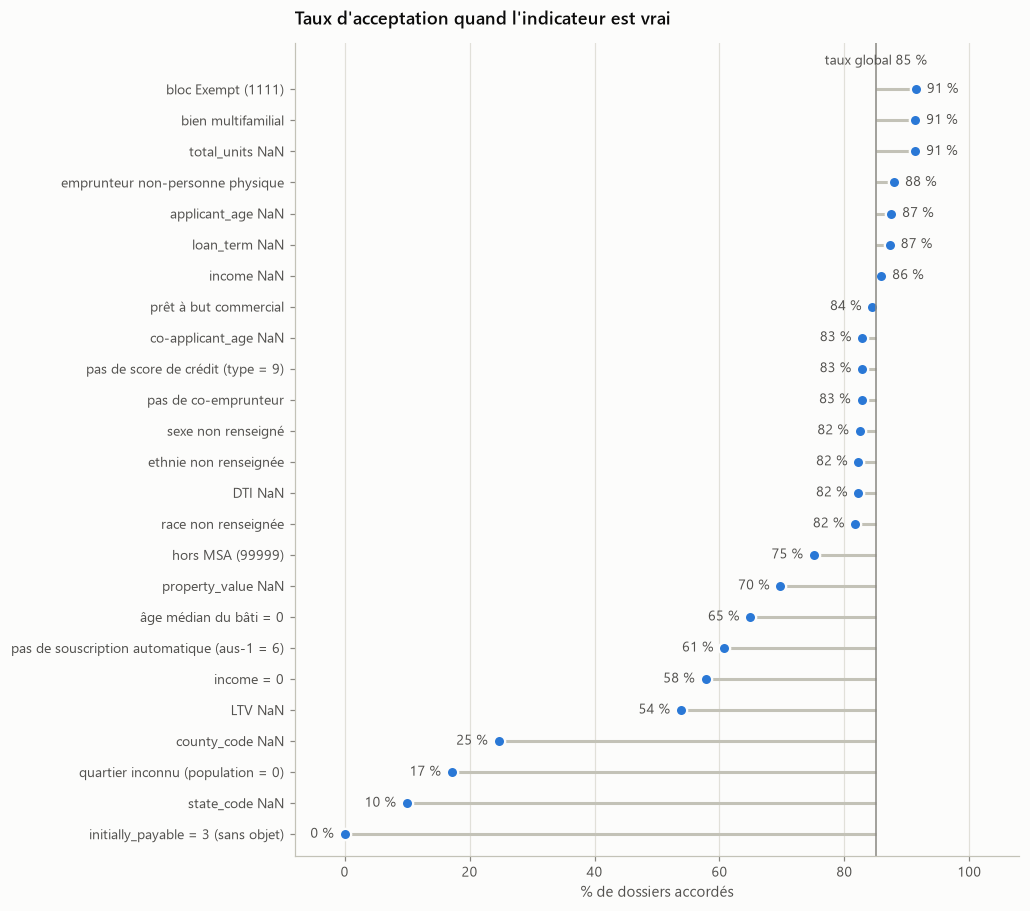

In [16]:
def target_flags(df):
    """Indicateurs de la section 3.3 complétés par quelques codes spéciaux de la section 3.2."""
    extra = pd.DataFrame({
        "pas de souscription automatique (aus-1 = 6)": df["aus-1"] == 6,
        "initially_payable = 3 (sans objet)": df["initially_payable_to_institution"] == 3,
        "pas de score de crédit (type = 9)": df["applicant_credit_score_type"] == 9,
        "income = 0": df["income"] == 0,
        "ethnie non renseignée": df["applicant_ethnicity-1"] == 3,
        "race non renseignée": df["applicant_race-1"] == 6,
        "sexe non renseigné": df["applicant_sex"] == 3,
        "âge médian du bâti = 0": df["tract_median_age_of_housing_units"] == 0,
    })
    return pd.concat([missing_flags(df), extra], axis=1)


tflags, tflags_test = target_flags(train), target_flags(test)
base_rate = train[TARGET].mean() * 100

link = pd.DataFrame({
    "n": tflags.sum(),
    "% train": tflags.mean() * 100,
    "% test": tflags_test.mean() * 100,
    "taux si vrai": [train.loc[tflags[c], TARGET].mean() * 100 for c in tflags],
    "taux si faux": [train.loc[~tflags[c], TARGET].mean() * 100 for c in tflags],
})
link["écart (pts)"] = link["taux si vrai"] - link["taux si faux"]
link = link.sort_values("taux si vrai")
print(f"Taux d'acceptation global : {base_rate:.1f} %")
display(link)

# Graphique : écart au taux global, une ligne par indicateur
fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(link) + 1.6))
y = np.arange(len(link))
ax.hlines(y, base_rate, link["taux si vrai"], color=AXIS, linewidth=2, zorder=1)
ax.scatter(link["taux si vrai"], y, s=55, color=PALETTE[0], edgecolor=SURFACE, linewidth=1.5, zorder=2)
ax.axvline(base_rate, color=MUTED, linewidth=1)
ax.text(base_rate, len(link) - 0.3, f"taux global {base_rate:.0f} %", ha="center", va="bottom", fontsize=9, color=INK_2)
for yi, rate in zip(y, link["taux si vrai"]):
    side = -1 if rate < base_rate else 1
    ax.text(rate + side * 1.8, yi, f"{rate:.0f} %", va="center", ha="right" if side < 0 else "left",
            fontsize=9, color=INK_2)

ax.set_yticks(y, link.index)
ax.set(title="Taux d'acceptation quand l'indicateur est vrai", xlabel="% de dossiers accordés", xlim=(-8, 108),
       ylim=(-0.7, len(link) + 0.5))
ax.grid(axis="y", visible=False)
plt.show()

In [17]:
# Un même NaN peut recouvrir deux populations : ici, les dossiers Exempt et les autres
by_exempt = (
    train[tflags["LTV NaN"]]
    .groupby(tflags.loc[tflags["LTV NaN"], "bloc Exempt (1111)"])[TARGET]
    .agg(n="size", taux_acceptation="mean")
    .rename(index={True: "LTV NaN, dossier Exempt", False: "LTV NaN, dossier non Exempt"})
    .rename_axis(None)
)
by_exempt["taux_acceptation"] *= 100
by_exempt

,n,taux_acceptation
"LTV NaN, dossier non Exempt",8885,41.19
"LTV NaN, dossier Exempt",2989,91.37


### 3.5 Vérifications avant de créer des variables

**Co-emprunteur.** Six colonnes ont un code dédié « No co-applicant ». Avant de créer `has_coapplicant`, on vérifie qu'elles sont d'accord entre elles, pour ne pas confondre « pas de co-emprunteur » et « co-emprunteur dont on ne sait rien ».

In [18]:
NO_COAPP_CODES = {
    "co-applicant_sex": 5, "co-applicant_race-1": 8, "co-applicant_ethnicity-1": 5,
    "co-applicant_sex_observed": 4, "co-applicant_race_observed": 4, "co-applicant_ethnicity_observed": 4,
}
COAPP_COLS = list(NO_COAPP_CODES) + ["co-applicant_age", "co-applicant_credit_score_type"]


def no_coapp_votes(df):
    """Nombre de colonnes (sur 6) qui déclarent l'absence de co-emprunteur."""
    return sum((df[col] == code).astype(int) for col, code in NO_COAPP_CODES.items())


votes_train, votes_test = no_coapp_votes(train), no_coapp_votes(test)
votes = pd.DataFrame({"train": votes_train.value_counts(), "test": votes_test.value_counts()}).sort_index()
votes["% train"] = votes["train"] / len(train) * 100
display(votes.rename_axis("colonnes disant « pas de co-emprunteur » (sur 6)"))

print("Exemples à 4 colonnes sur 6 :")
display(train.loc[votes_train == 4, COAPP_COLS].head(4))
print("Exemples à 2 colonnes sur 6 :")
display(train.loc[votes_train == 2, COAPP_COLS].head(4))

,train,test,% train
colonnes disant « pas de co-emprunteur » (sur 6),,,
0,47404,20361,45.15
2,13,5,0.01
4,118,51,0.11
6,57465,24583,54.73


Exemples à 4 colonnes sur 6 :


,co-applicant_sex,co-applicant_race-1,co-applicant_ethnicity-1,co-applicant_sex_observed,co-applicant_race_observed,co-applicant_ethnicity_observed,co-applicant_age,co-applicant_credit_score_type
796,5,8.00,4.00,4,4,3,NaN,9
1511,4,8.00,5.00,3,4,4,NaN,1111
3514,5,7.00,5.00,4,3,4,NaN,10
4292,5,6.00,5.00,4,2,4,NaN,10


Exemples à 2 colonnes sur 6 :


,co-applicant_sex,co-applicant_race-1,co-applicant_ethnicity-1,co-applicant_sex_observed,co-applicant_race_observed,co-applicant_ethnicity_observed,co-applicant_age,co-applicant_credit_score_type
15332,5,2.00,2.00,4,2,2,<25,5
16893,5,5.00,4.00,4,3,3,NaN,9
25555,2,8.00,1.00,2,4,2,25-34,1
33588,2,7.00,5.00,1,3,4,35-44,1


In [19]:
def has_coapplicant(df):
    """1 si un co-emprunteur existe ; 0 si la majorité des 6 colonnes déclare qu'il n'y en a pas."""
    return (no_coapp_votes(df) < 4).astype(int)


# Les cas de désaccord vont-ils dans le sens de la règle ? L'âge du co-emprunteur sert de juge indépendant.
check = pd.DataFrame({
    "votes": votes_train,
    "has_coapplicant": has_coapplicant(train),
    "âge du co-emprunteur connu": train["co-applicant_age"].notna(),
})
display(check.groupby(["votes", "has_coapplicant"])["âge du co-emprunteur connu"].agg(n="size", part_age_connu="mean"))

# Statut du co-emprunteur : on sépare "il n'y en a pas" de "il y en a un mais on ne sait pas"
hc = has_coapplicant(train).astype(bool)
age_nan = train["co-applicant_age"].isna()
coapp_status = pd.Series(
    np.select(
        [~hc, ~age_nan, train["co-applicant_sex"] == 4],
        ["pas de co-emprunteur", "co-emprunteur, âge connu", "co-emprunteur non-personne physique (âge sans objet)"],
        default="co-emprunteur, âge réellement manquant",
    ),
    index=train.index,
)
display(pd.DataFrame({
    "n": coapp_status.value_counts(),
    "% des lignes": coapp_status.value_counts(normalize=True) * 100,
    "taux d'acceptation": train.groupby(coapp_status)[TARGET].mean() * 100,
}).sort_values("n", ascending=False))

# co-applicant_credit_score_type = 10 dit aussi "No co-applicant", mais il est écrasé par d'autres codes
print("Type de score du co-emprunteur quand il n'y a pas de co-emprunteur :")
print(decode(train[~hc], "co-applicant_credit_score_type").value_counts().to_string())

,,n,part_age_connu
votes,has_coapplicant,,
0,1,47404,0.98
2,1,13,0.46
4,0,118,0.00
6,0,57465,0.00


,n,% des lignes,taux d'acceptation
pas de co-emprunteur,57583,54.84,82.74
"co-emprunteur, âge connu",46303,44.10,87.71
co-emprunteur non-personne physique (âge sans objet),1007,0.96,90.57
"co-emprunteur, âge réellement manquant",107,0.10,69.16


Type de score du co-emprunteur quand il n'y a pas de co-emprunteur :
co-applicant_credit_score_type
No co-applicant                       55738
Exempt                                 1633
Not applicable                          207
More than one credit scoring model        4
Equifax Beacon 5.0                        1


**Emprunteur société.** Une colonne « business » existe déjà : `business_or_commercial_purpose`. Mais elle décrit l'**objet du prêt**, pas la nature de l'emprunteur. On vérifie si elle recoupe l'indicateur « emprunteur non-personne physique » (`applicant_sex = 4`, « Not applicable »).

In [20]:
def applicant_not_person(df):
    """1 si l'emprunteur n'est pas une personne physique (sexe déclaré « Not applicable »)."""
    return (df["applicant_sex"] == 4).astype(int)


not_person = applicant_not_person(train).astype(bool)

# Les trois colonnes de profil donnent-elles le même signal « Not applicable » ?
same_signal = pd.DataFrame({
    "sexe = 4": not_person,
    "ethnie = 4": train["applicant_ethnicity-1"] == 4,
    "race = 7": train["applicant_race-1"] == 7,
})
print(f"Not applicable sur les 3 colonnes à la fois : {same_signal.all(axis=1).sum():,}")
print(f"Not applicable sur au moins une colonne     : {same_signal.any(axis=1).sum():,}")

# Objet du prêt (colonne existante) vs nature de l'emprunteur (nouvel indicateur)
purpose = decode(train, "business_or_commercial_purpose").rename("prêt à but commercial")
display(pd.crosstab(purpose, not_person.rename("emprunteur non-personne physique"), margins=True))

display(
    train.groupby([purpose, not_person.rename("emprunteur non-personne physique")])[TARGET]
    .agg(n="size", taux_acceptation="mean")
    .assign(taux_acceptation=lambda d: d["taux_acceptation"] * 100)
)

Not applicable sur les 3 colonnes à la fois : 2,907
Not applicable sur au moins une colonne     : 2,923


emprunteur non-personne physique,False,True,All
prêt à but commercial,,,
Exempt,2372,598,2970
Non,95211,27,95238
Oui,4507,2285,6792
All,102090,2910,105000


n  \
prêt à but commercial emprunteur non-personne physique          
Exempt                False                              2372   
                      True                                598   
Non                   False                             95211   
                      True                                 27   
Oui                   False                              4507   
                      True                               2285   

                                                        taux_acceptation  
prêt à but commercial emprunteur non-personne physique                    
Exempt                False                                        89.88  
                      True                                         97.16  
Non                   False                                        84.83  
                      True                                         85.19  
Oui                   False                                        83.94  
                      True                                         85.56

### 3.6 À retenir

**Ampleur.** 15 variables ont des NaN, mais 41 sur 56 ont des valeurs inconnues une fois comptés les codes. Hors `co-applicant_age`, 16,5 % des lignes ont au moins un NaN.

**Les manquants ne tombent pas au hasard : ils forment quatre blocs.**

| Bloc | Lignes | Ce qui manque | Explication |
|---|---|---|---|
| Exempt | 3 016 (2,9 %) | 14 champs à `1111`, et LTV, DTI, durée en NaN sur 99 % de ces lignes | établissement dispensé de déclaration |
| Emprunteur non-personne physique | 2 910 (2,8 %) | âge et revenu | une société n'a ni âge ni revenu déclaré |
| Localisation inconnue | environ 2 100 (2 %) | état, comté, variables de quartier à 0 | bien non localisé |
| Structurel | 437 et 57 583 | `total_units`, `conforming_loan_limit`, `co-applicant_age` | bien multifamilial ; pas de co-emprunteur |

**Le fait d'être manquant est un signal fort pour la cible** (taux global : 85 %).
- Localisation inconnue : 10 à 25 % d'acceptation.
- LTV manquant hors bloc Exempt : 41 %, contre 91 % pour le LTV manquant des dossiers Exempt. Le même NaN recouvre donc deux populations opposées.
- `aus-1 = 6` (pas de souscription automatique) : 61 %, sur 21 % des dossiers.
- `initially_payable_to_institution = 3` : 0 % d'acceptation sur 1 566 dossiers. Le code existe aussi dans le test (1,4 %).
- À l'inverse, le bloc Exempt est accepté à 91 %.

Une lecture plausible : un dossier refusé tôt n'est jamais complété, donc ses champs restent vides. Ce n'est pas démontré ici, mais cela suffit à écarter l'hypothèse de manquants aléatoires.

**Vérifications (3.5)**
- Les six colonnes « No co-applicant » sont d'accord sur 99,9 % des lignes (131 désaccords dans le train). Règle retenue : pas de co-emprunteur si au moins 4 colonnes sur 6 le disent. L'âge du co-emprunteur, qui n'entre pas dans la règle, la confirme : il n'est presque jamais renseigné quand la règle dit « pas de co-emprunteur ».
- `co-applicant_credit_score_type = 10` n'est pas utilisé dans la règle : il est remplacé par `1111` sur les dossiers Exempt.
- Parmi les dossiers avec co-emprunteur, l'âge manque 1 114 fois : 1 007 fois parce que le co-emprunteur n'est pas une personne physique (sans objet), et seulement 107 fois sans raison (vrai manquant, 69 % d'acceptation).
- `business_or_commercial_purpose` décrit l'objet du prêt, pas l'emprunteur : seul un tiers des prêts à but commercial (2 285 sur 6 792) a un emprunteur non-personne physique. `applicant_not_person` apporte donc une information distincte.

**Point ouvert** : `tract_median_age_of_housing_units = 0` (6,2 % des lignes, 65 % d'acceptation). Inconnu, ou quartier neuf ? À regarder à l'étape 4.

**Décisions retenues pour le pipeline (étape 8)**

Principe : `1111` (Exempt), « sans objet » et « non renseigné » sont des informations, on les garde comme modalités telles quelles. Le travail d'imputation ne porte que sur les **NaN purs**.

1. Ne supprimer aucune ligne.
2. Créer `has_coapplicant` (règle des 4 colonnes sur 6) et `applicant_not_person` (`applicant_sex = 4`).
3. `co-applicant_age` : trois cas distincts. NaN → « pas de co-emprunteur » quand il n'y en a pas ; → « sans objet » quand le co-emprunteur n'est pas une personne physique ; reste NaN sinon (107 lignes).
4. `applicant_age` NaN → « sans objet » quand l'emprunteur n'est pas une personne physique ; il reste 179 vrais manquants.
5. `total_units` NaN → 5 (bien multifamilial) ; `conforming_loan_limit` NaN → modalité « NA » (mêmes 437 lignes).
6. Variables de quartier : les 0 sont de fausses valeurs, on les remplace par NaN pour qu'ils soient traités avec les autres NaN purs.
7. Pas d'indicateur `is_exempt`, `geo_unknown` ou `*_missing` : l'information est déjà portée par les modalités `1111` et par les NaN eux-mêmes. À rediscuter seulement si on impute pour un modèle linéaire, car l'imputation efface le NaN.

## 4. Variables numériques et outliers

Quatre questions :
1. Les 0 de `tract_median_age_of_housing_units` sont-ils de vraies valeurs (point laissé ouvert à l'étape 3) ?
2. À quoi ressemblent les distributions, et où sont les valeurs extrêmes ?
3. Ces valeurs extrêmes sont-elles des erreurs ou de vrais dossiers ? Sont-elles aussi dans le test ?
4. `loan_to_value_ratio` est-il cohérent avec `loan_amount / property_value` ?

### 4.1 Point ouvert : âge médian du bâti à 0

In [21]:
age = train["tract_median_age_of_housing_units"]
print("Plus petites valeurs observées :", sorted(age.unique())[:6])
print("Effectifs :", age.value_counts().sort_index().loc[:9].to_dict())

age_group = pd.Series(
    np.select(
        [(age <= 0) & (train["tract_population"] == 0), age <= 0],
        ["âge <= 0, quartier inconnu (population = 0)", "âge <= 0, quartier connu"],
        default="âge > 0",
    ),
    index=train.index,
)
pd.DataFrame({
    "n": age_group.value_counts(),
    "% des lignes": age_group.value_counts(normalize=True) * 100,
    "taux d'acceptation": train.groupby(age_group)[TARGET].mean() * 100,
})

Plus petites valeurs observées : [np.int64(-1), np.int64(0), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Effectifs : {-1: 5, 0: 6507, 6: 1097, 7: 294, 8: 422, 9: 499}


,n,% des lignes,taux d'acceptation
"âge <= 0, quartier connu",4395,4.19,87.99
"âge <= 0, quartier inconnu (population = 0)",2117,2.02,17.15
âge > 0,98488,93.80,86.32


Aucune valeur entre 1 et 5 ans, et un pic à 6 ans (près de quatre fois plus de dossiers qu'à 7). C'est cohérent avec une source qui regroupe les valeurs basses dans une catégorie plancher : 0 ne serait alors pas un vrai âge mais un code « non disponible ». Ce n'est cependant pas démontré.

Décision : **on garde le 0** quand le quartier est connu. Pour un modèle à arbres, 0 ou NaN revient presque au même, puisque 0 est sous toutes les autres valeurs. Seul le cas « quartier inconnu » (toutes les variables de quartier à 0) passe en NaN, comme décidé à l'étape 3.

### 4.2 Nettoyage des fausses valeurs et statistiques descriptives

In [22]:
def clean_tract(df):
    """Quartier inconnu (population à 0) : toutes les variables de quartier passent en NaN."""
    out = df.copy()
    out[TRACT_COLS] = out[TRACT_COLS].astype(float)
    out.loc[out["tract_population"] == 0, TRACT_COLS] = np.nan
    return out


num = clean_tract(train)[NUM_COLS]
num_test = clean_tract(test)[NUM_COLS]

desc = num.describe(percentiles=[0.01, 0.5, 0.99]).T[["count", "min", "1%", "50%", "99%", "max"]]
desc["max / médiane"] = desc["max"] / desc["50%"]
desc["asymétrie"] = num.skew()
desc["max (test)"] = num_test.max()
desc

,count,min,1%,50%,99%,max,max / médiane,asymétrie,max (test)
loan_amount,"105,000.00","5,000.00","5,000.00","285,000.00","1,615,000.00","375,005,000.00","1,315.81",140.75,"156,105,000.00"
loan_to_value_ratio,"93,126.00",0.50,23.23,90.00,104.72,"600,000,000.00","6,666,666.67",305.17,705.00
property_value,"100,244.00","5,000.00","55,000.00","355,000.00","2,340,700.00","1,581,075,000.00","4,453.73",233.25,"222,005,000.00"
income,"100,422.00",-657.00,4.00,107.00,827.79,"71,000.00",663.55,97.71,"16,031.00"
loan_term,"101,693.00",1.00,12.00,360.00,364.00,480.00,1.33,-3.36,480.00
total_units,"104,563.00",1.00,1.00,1.00,2.00,4.00,4.00,8.10,4.00
tract_population,"102,883.00",1.00,"1,441.82","4,542.00","12,149.00","30,199.00",6.65,2.59,"30,199.00"
tract_minority_population_percent,"102,883.00",0.00,4.76,30.51,98.19,100.00,3.28,0.78,100.00
ffiec_msa_md_median_family_income,"102,883.00","23,800.00","63,100.00","97,600.00","164,200.00","201,300.00",2.06,0.91,"201,300.00"
tract_to_msa_income_percentage,"102,883.00",0.00,35.00,104.00,242.00,516.00,4.96,1.06,412.00


### 4.3 Boxplots

Sur les quatre variables les plus asymétriques, le boxplot en échelle brute est illisible : quelques valeurs géantes écrasent la boîte. L'échelle log rend la distribution lisible, sans rien supprimer.

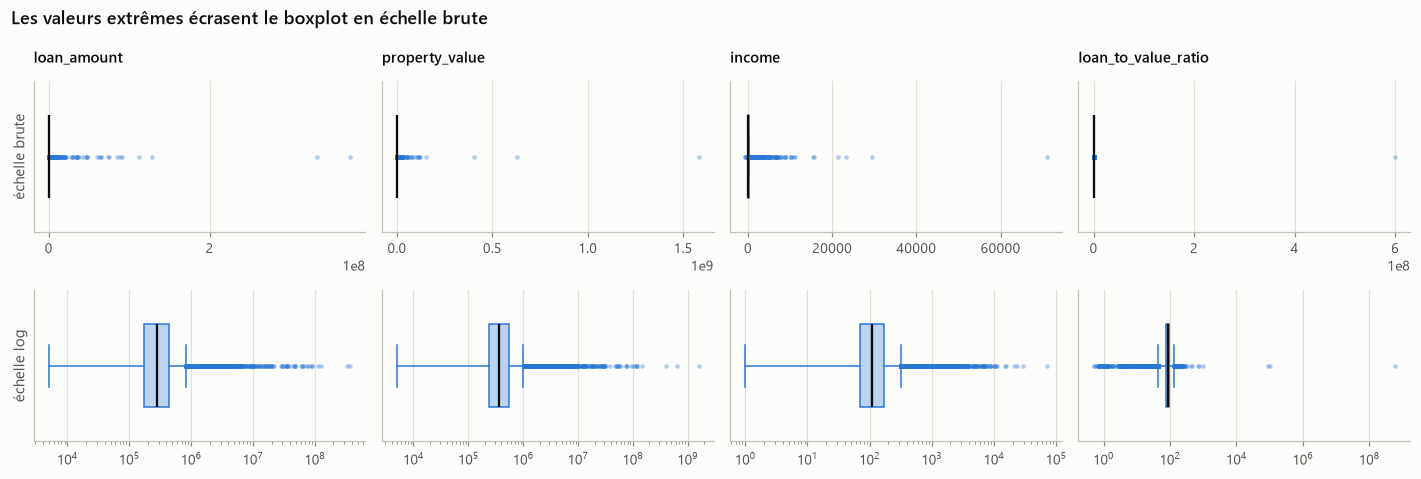

In [23]:
SKEWED = ["loan_amount", "property_value", "income", "loan_to_value_ratio"]


def box_style(color):
    """Style commun des boxplots : boîte en teinte claire, contours et points dans la couleur de la série."""
    return dict(
        orientation="horizontal", widths=0.55, patch_artist=True,
        boxprops=dict(facecolor=mpl.colors.to_rgba(color, 0.3), edgecolor=color),
        medianprops=dict(color=INK, linewidth=1.5),
        whiskerprops=dict(color=color), capprops=dict(color=color),
        flierprops=dict(marker="o", markersize=3, markerfacecolor=color, markeredgecolor="none", alpha=0.35),
    )


fig, axes = plt.subplots(2, 4, figsize=(13, 4.4))
for j, col in enumerate(SKEWED):
    values = num[col].dropna()
    axes[0, j].boxplot(values, **box_style(PALETTE[0]))
    axes[0, j].set_title(col, fontsize=10)
    axes[0, j].locator_params(axis="x", nbins=4)
    axes[1, j].boxplot(values[values > 0], **box_style(PALETTE[0]))
    axes[1, j].set_xscale("log")
for ax in axes.ravel():
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0, 0].set_ylabel("échelle brute")
axes[1, 0].set_ylabel("échelle log")
fig.suptitle("Les valeurs extrêmes écrasent le boxplot en échelle brute", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
plt.show()

Boxplots par classe de la cible, pour toutes les variables continues. Les points extrêmes sont masqués ici pour comparer les boîtes ; `loan_term` et `total_units` sont exclus car presque constants (81 % des prêts durent 360 mois, 97 % des biens ont un seul logement).

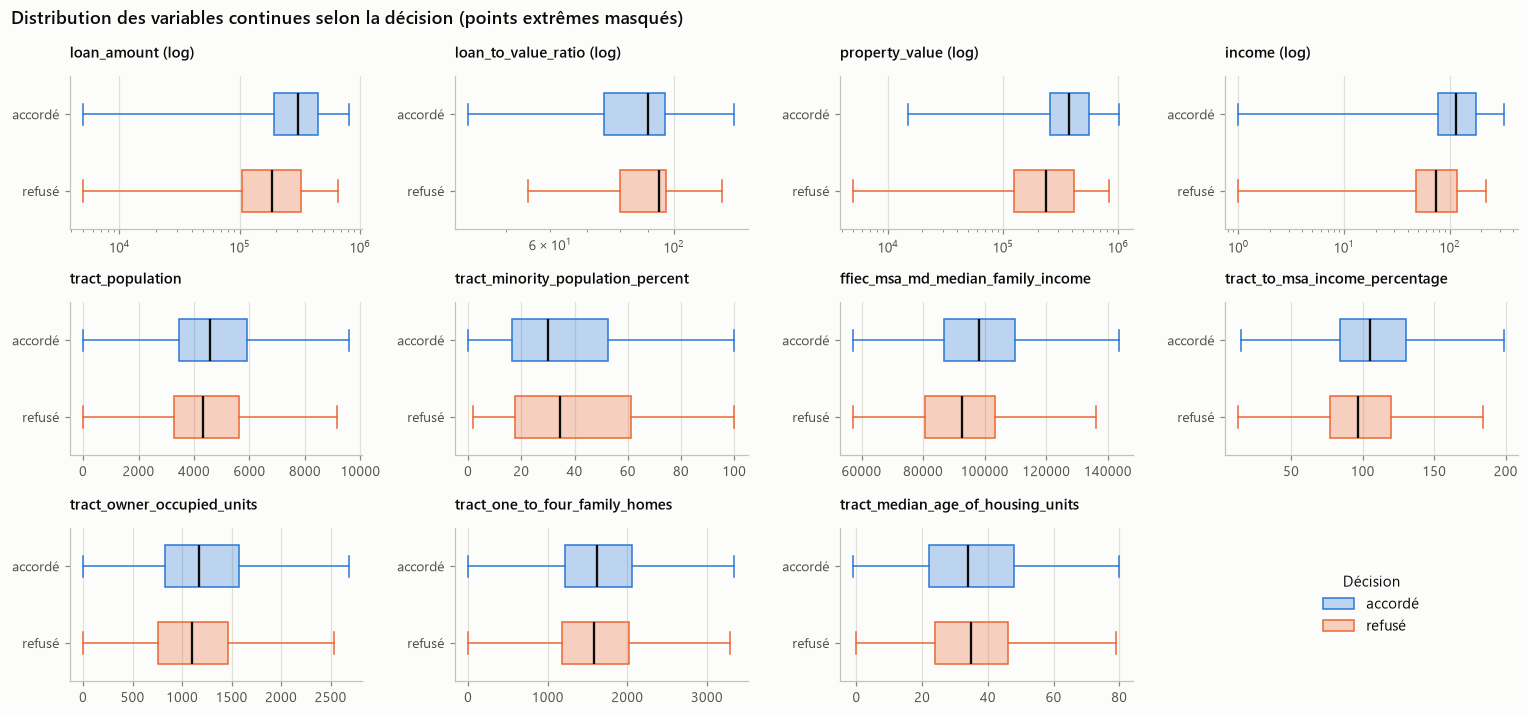

In [24]:
TARGET_LABELS = {1: "accordé", 0: "refusé"}
TARGET_COLORS = {1: PALETTE[0], 0: PALETTE[1]}
BOX_COLS = [c for c in NUM_COLS if c not in ("loan_term", "total_units")]

fig, axes = plt.subplots(3, 4, figsize=(14, 6.6))
for ax, col in zip(axes.ravel(), BOX_COLS):
    for pos, cls in enumerate([0, 1]):
        values = num.loc[train[TARGET] == cls, col].dropna()
        if col in SKEWED:
            values = values[values > 0]
        ax.boxplot(values, positions=[pos], showfliers=False, **box_style(TARGET_COLORS[cls]))
    if col in SKEWED:
        ax.set_xscale("log")
    ax.set_title(col + (" (log)" if col in SKEWED else ""), fontsize=10)
    ax.set_yticks([0, 1], [TARGET_LABELS[0], TARGET_LABELS[1]])
    ax.grid(axis="y", visible=False)

# La case restante porte la légende
legend_ax = axes.ravel()[len(BOX_COLS)]
legend_ax.axis("off")
legend_ax.legend(
    handles=[mpl.patches.Patch(facecolor=mpl.colors.to_rgba(TARGET_COLORS[c], 0.3),
                                          edgecolor=TARGET_COLORS[c], label=TARGET_LABELS[c]) for c in (1, 0)],
    title="Décision", loc="center", fontsize=10,
)
fig.suptitle("Distribution des variables continues selon la décision (points extrêmes masqués)", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
plt.show()

### 4.4 Combien d'outliers, et sont-ils des erreurs ?

Règle classique du boxplot : une valeur est un outlier si elle sort de l'intervalle [Q1 − 1,5 × IQR ; Q3 + 1,5 × IQR]. On l'applique en échelle brute et en échelle log, et on regarde le taux d'acceptation des outliers.

In [25]:
def iqr_outliers(s):
    """Vrai pour les valeurs hors de [Q1 - 1,5 IQR ; Q3 + 1,5 IQR]."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)


rows = []
for col in NUM_COLS:
    out = iqr_outliers(num[col])
    out_log = iqr_outliers(np.log1p(num[col].clip(lower=0)))
    rows.append({
        "variable": col,
        "n outliers (brut)": out.sum(),
        "% outliers (brut)": out.mean() * 100,
        "% outliers (log)": out_log.mean() * 100,
        "taux d'acceptation des outliers (brut)": train.loc[out, TARGET].mean() * 100,
    })
print(f"Taux d'acceptation global : {base_rate:.1f} %")
pd.DataFrame(rows).set_index("variable")

Taux d'acceptation global : 85.0 %


,n outliers (brut),% outliers (brut),% outliers (log),taux d'acceptation des outliers (brut)
variable,,,,
loan_amount,4931,4.70,4.36,89.23
loan_to_value_ratio,4023,3.83,6.18,89.14
property_value,6349,6.05,3.21,90.12
income,7500,7.14,3.20,92.17
loan_term,16184,15.41,15.41,58.24
total_units,2875,2.74,2.74,83.37
tract_population,2946,2.81,1.99,87.78
tract_minority_population_percent,0,0.00,0.02,NaN
ffiec_msa_md_median_family_income,4900,4.67,1.94,89.90


In [26]:
# Valeurs suspectes : fréquence dans le train et le test, et taux d'acceptation
def suspect_values(df):
    ltv, income = df["loan_to_value_ratio"], df["income"]
    return pd.DataFrame({
        "LTV > 1000": ltv > 1000,
        "LTV entre 150 et 1000": ltv.between(150, 1000),
        "LTV entre 105 et 150": ltv.between(105, 150, inclusive="left"),
        "income < 0": income < 0,
        "income = 0": income == 0,
        "income entre 0 et 20 k$": income.between(0, 20, inclusive="neither"),
        "income >= 5 M$": income >= 5000,
        "loan_amount >= 5 M$": df["loan_amount"] >= 5e6,
        "property_value >= 5 M$": df["property_value"] >= 5e6,
        "loan_term < 12 mois": df["loan_term"] < 12,
    })


susp, susp_test = suspect_values(train), suspect_values(test)
display(pd.DataFrame({
    "n train": susp.sum(),
    "n test": susp_test.sum(),
    "taux d'acceptation": [train.loc[susp[c], TARGET].mean() * 100 for c in susp],
}))

print("Les dossiers à LTV > 1000 :")
display(train.loc[susp["LTV > 1000"], ["loan_amount", "property_value", "loan_to_value_ratio", "lien_status", TARGET]])

,n train,n test,taux d'acceptation
LTV > 1000,3,0,0.00
LTV entre 150 et 1000,113,47,72.57
LTV entre 105 et 150,733,352,59.48
income < 0,28,20,0.00
income = 0,926,376,57.78
income entre 0 et 20 k$,701,287,33.67
income >= 5 M$,41,16,90.24
loan_amount >= 5 M$,124,44,86.29
property_value >= 5 M$,216,85,86.11
loan_term < 12 mois,146,70,87.67


Les dossiers à LTV > 1000 :


,loan_amount,property_value,loan_to_value_ratio,lien_status,accepted
31618,"65,000.00",NaN,"600,000,000.00",2,0
81299,"35,000.00","5,000.00","92,092.31",2,0
85341,"155,000.00","5,000.00","99,999.90",2,0


Recherche plus large de valeurs absurdes : les plus grandes valeurs, et des contrôles de cohérence entre colonnes (train et test).

In [27]:
SHOW_COLS = ["loan_amount", "property_value", "loan_to_value_ratio", "income", "loan_term",
             "derived_dwelling_category", "applicant_sex", TARGET]
print("Plus gros prêts :")
display(train.nlargest(5, "loan_amount")[SHOW_COLS])
print("Plus gros revenus (en milliers de $) :")
display(train.nlargest(5, "income")[SHOW_COLS])


def coherence_checks(df):
    ratio = df["loan_amount"] / df["property_value"]
    income_usd = (df["income"] * 1000).where(df["income"] > 0)
    return pd.DataFrame({
        "LTV > 200": df["loan_to_value_ratio"] > 200,
        "valeur du bien = 5 000 $": df["property_value"] == 5000,
        "prêt > 10 x valeur du bien": ratio > 10,
        "prêt > 100 x revenu annuel": df["loan_amount"] > 100 * income_usd,
        "revenu >= 10 M$ par an": df["income"] >= 10000,
        "durée <= 3 mois": df["loan_term"] <= 3,
    })


chk, chk_test = coherence_checks(train), coherence_checks(test)
pd.DataFrame({
    "n train": chk.sum(),
    "n test": chk_test.sum(),
    "taux d'acceptation": [train.loc[chk[c], TARGET].mean() * 100 for c in chk],
})

Plus gros prêts :


,loan_amount,property_value,loan_to_value_ratio,income,loan_term,derived_dwelling_category,applicant_sex,accepted
98639,"375,005,000.00","626,705,000.00",59.80,NaN,3.00,Multifamily:Site-Built,4,1
89066,"333,965,000.00","405,405,000.00",727.68,NaN,24.00,Multifamily:Site-Built,4,1
101287,"127,815,000.00",NaN,NaN,NaN,NaN,Multifamily:Site-Built,4,1
91836,"112,005,000.00",NaN,NaN,NaN,60.00,Multifamily:Site-Built,4,0
59098,"91,005,000.00","118,205,000.00",40.40,NaN,36.00,Multifamily:Site-Built,4,1


Plus gros revenus (en milliers de $) :


,loan_amount,property_value,loan_to_value_ratio,income,loan_term,derived_dwelling_category,applicant_sex,accepted
36590,"185,000.00",NaN,NaN,"71,000.00",NaN,Single Family (1-4 Units):Site-Built,1,1
43834,"13,005,000.00","26,505,000.00",49.00,"29,560.00",24.00,Single Family (1-4 Units):Site-Built,1,1
29024,"975,000.00","1,375,000.00",70.90,"23,340.00",180.00,Single Family (1-4 Units):Site-Built,2,1
47236,"755,000.00","1,505,000.00",50.00,"21,354.00",360.00,Single Family (1-4 Units):Site-Built,1,1
4,"1,775,000.00","2,955,000.00",60.00,"15,675.00",360.00,Single Family (1-4 Units):Site-Built,1,0


,n train,n test,taux d'acceptation
LTV > 200,34,8,58.82
valeur du bien = 5 000 $,16,8,0.00
prêt > 10 x valeur du bien,21,10,9.52
prêt > 100 x revenu annuel,28,15,39.29
revenu >= 10 M$ par an,11,2,90.91
durée <= 3 mois,4,3,75.00


### 4.5 Cohérence du LTV et ratios dérivés

Le LTV (*loan-to-value*) est en principe le montant du prêt rapporté à la valeur du bien. On le compare au ratio recalculé `loan_amount / property_value × 100`, séparément selon le rang de l'hypothèque.

,n,LTV médian,ratio recalculé médian,% à moins de 5 points d'écart
lien_status,,,,
First lien,88402,90.00,88.07,94.33
Subordinate lien,4241,99.79,5.88,5.26


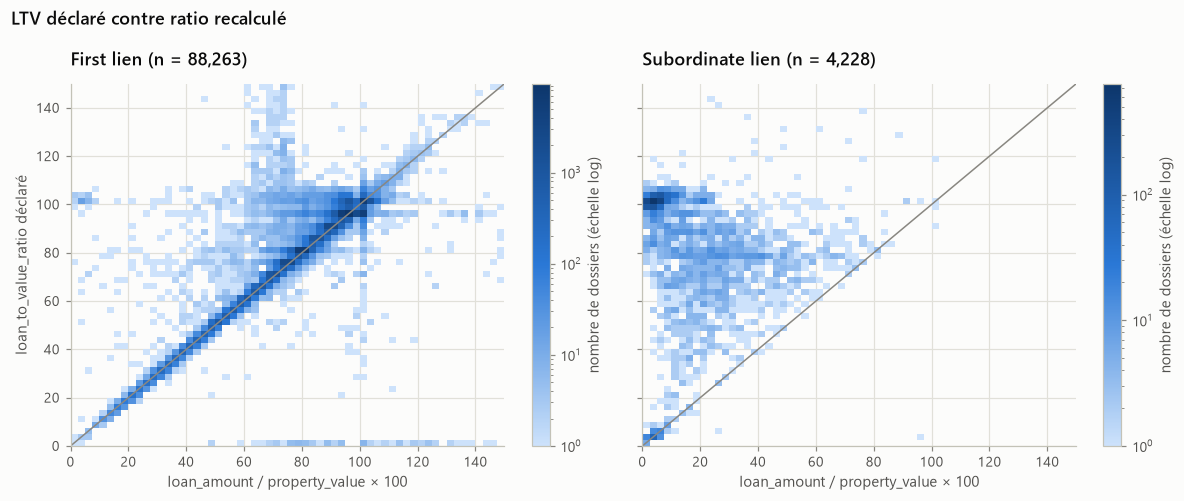

LTV manquant mais ratio recalculable : 7,601 dossiers (taux d'acceptation 42.9%)


In [28]:
ltv = train["loan_to_value_ratio"]
ratio = train["loan_amount"] / train["property_value"] * 100
lien = decode(train, "lien_status")
both = ltv.notna() & ratio.notna()

display(pd.DataFrame({
    "n": both.groupby(lien).sum(),
    "LTV médian": ltv[both].groupby(lien[both]).median(),
    "ratio recalculé médian": ratio[both].groupby(lien[both]).median(),
    "% à moins de 5 points d'écart": ((ltv - ratio).abs() < 5)[both].groupby(lien[both]).mean() * 100,
}))

sequential = sns.blend_palette(["#cde2fb", "#2a78d6", "#0d366b"], as_cmap=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, status in zip(axes, ["First lien", "Subordinate lien"]):
    sel = both & (lien == status) & (ltv <= 150) & (ratio <= 150)
    *_, image = ax.hist2d(ratio[sel], ltv[sel], bins=60, range=[[0, 150], [0, 150]], cmap=sequential,
                          norm=mpl.colors.LogNorm(), cmin=1)
    ax.plot([0, 150], [0, 150], color=MUTED, linewidth=1)
    ax.set(title=f"{status} (n = {sel.sum():,})", xlabel="loan_amount / property_value × 100")
    fig.colorbar(image, ax=ax, label="nombre de dossiers (échelle log)")
axes[0].set_ylabel("loan_to_value_ratio déclaré")
fig.suptitle("LTV déclaré contre ratio recalculé", x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
plt.show()

recomputable = ltv.isna() & ratio.notna()
print(f"LTV manquant mais ratio recalculable : {recomputable.sum():,} dossiers "
      f"(taux d'acceptation {train.loc[recomputable, TARGET].mean():.1%})")

Le graphique de gauche montre une bande horizontale tout en bas : des LTV déclarés proches de 0 alors que le ratio recalculé est élevé. On regarde ces dossiers.

In [29]:
def ltv_as_fraction(df):
    """LTV saisi en fraction (0,82) au lieu d'un pourcentage (82)."""
    return df["loan_to_value_ratio"] < 1.5


frac = ltv_as_fraction(train)
close = ((ltv * 100 - ratio).abs() < 10)[frac & ratio.notna()].mean()
print(f"LTV < 1,5 : {frac.sum()} dossiers dans le train, {ltv_as_fraction(test).sum()} dans le test")
print(f"LTV × 100 à moins de 10 points du ratio recalculé : {close:.0%} de ces dossiers")
train.loc[frac, ["loan_amount", "property_value", "loan_to_value_ratio", "lien_status", TARGET]].assign(
    ratio_recalcule=ratio[frac]
).head(6)

LTV < 1,5 : 83 dossiers dans le train, 44 dans le test
LTV × 100 à moins de 10 points du ratio recalculé : 91% de ces dossiers


,loan_amount,property_value,loan_to_value_ratio,lien_status,accepted,ratio_recalcule
3907,"165,000.00","195,000.00",0.82,1,1,84.62
4949,"185,000.00","155,000.00",1.21,1,1,119.35
6547,"95,000.00","75,000.00",1.30,1,1,126.67
6934,"85,000.00","95,000.00",0.87,1,1,89.47
7171,"155,000.00","195,000.00",0.80,1,1,79.49
7733,"145,000.00","185,000.00",0.76,1,1,78.38


La plupart sont des LTV saisis en fraction (0,82 au lieu de 82). Mais quelques-uns sont de vrais LTV d'environ 1 % (un prêt de 5 000 $ sur un bien à 425 000 $). On ne corrige donc que les dossiers où le LTV multiplié par 100 retombe sur le ratio recalculé, à 10 points près.

In [30]:
def fix_ltv_fraction(df):
    """Multiplie par 100 les LTV saisis en fraction, quand le ratio recalculé le confirme."""
    out = df.copy()
    ltv = out["loan_to_value_ratio"]
    ratio = out["loan_amount"] / out["property_value"] * 100
    is_fraction = (ltv < 1.5) & ((ltv * 100 - ratio).abs() < 10)
    out.loc[is_fraction, "loan_to_value_ratio"] = ltv[is_fraction] * 100
    return out, is_fraction


fixed_train, fixed_mask = fix_ltv_fraction(train)
_, fixed_mask_test = fix_ltv_fraction(test)
print(f"LTV corrigés : {fixed_mask.sum()} dans le train, {fixed_mask_test.sum()} dans le test")
print(f"LTV < 1,5 restants (vrais petits LTV) : {(fixed_train['loan_to_value_ratio'] < 1.5).sum()} dans le train")
fixed_train.loc[fixed_mask, ["loan_amount", "property_value", "loan_to_value_ratio"]].assign(
    ltv_avant=train.loc[fixed_mask, "loan_to_value_ratio"]
).head(5)

LTV corrigés : 75 dans le train, 41 dans le test
LTV < 1,5 restants (vrais petits LTV) : 8 dans le train


,loan_amount,property_value,loan_to_value_ratio,ltv_avant
3907,"165,000.00","195,000.00",82.00,0.82
4949,"185,000.00","155,000.00",121.00,1.21
6547,"95,000.00","75,000.00",130.00,1.30
6934,"85,000.00","95,000.00",87.00,0.87
7171,"155,000.00","195,000.00",80.00,0.80


In [31]:
# Deuxième ratio classique : montant du prêt rapporté au revenu annuel (les deux en dollars)
loan_to_income = train["loan_amount"] / (train["income"].where(train["income"] > 0) * 1000)
bins = pd.cut(loan_to_income, [0, 1, 2, 3, 4, 5, 8, 20, np.inf], right=False)
pd.DataFrame({
    "n": bins.value_counts().sort_index(),
    "taux d'acceptation": train.groupby(bins, observed=True)[TARGET].mean() * 100,
}).rename_axis("loan_amount / income")

,n,taux d'acceptation
loan_amount / income,,
"[0.0, 1.0)",9994,81.60
"[1.0, 2.0)",19554,82.29
"[2.0, 3.0)",29185,88.33
"[3.0, 4.0)",24215,89.13
"[4.0, 5.0)",11808,87.25
"[5.0, 8.0)",3853,66.73
"[8.0, 20.0)",622,27.81
"[20.0, inf)",237,51.48


### 4.6 À retenir

**Âge médian du bâti à 0.** Probablement un code « non disponible » (aucune valeur entre 1 et 5 ans, pic à 6), mais ce n'est pas démontré. On garde le 0 quand le quartier est connu.

**Distributions.** Les montants (`loan_amount`, `property_value`, `income`) sont très asymétriques : le maximum vaut plus de 600 fois la médiane. L'échelle log les rend lisibles. Les variables de quartier sont bien plus régulières.

**Les outliers sont de vrais dossiers, pas des erreurs.**
- La règle du boxplot en classe 4 à 7 % sur les montants en échelle brute, et 3 à 4 % en échelle log.
- Leur taux d'acceptation est normal (89 à 92 %) et le test en contient autant. Les plus gros prêts (jusqu'à 375 M$) sont des immeubles multifamiliaux empruntés par des sociétés.
- `loan_term` fait exception : 15 % d'« outliers » acceptés à 58 %. La règle n'a pas de sens ici, puisque 81 % des prêts durent exactement 360 mois. C'est une variable quasi catégorielle, à traiter à l'étape 5.

**Les valeurs vraiment absurdes sont rares.**

| Anomalie | Train | Test | Décision |
|---|---|---|---|
| LTV > 1000 (jusqu'à 600 millions) | 3 | 0 | lignes supprimées |
| Revenu de 71 M$ par an pour un prêt de 185 k$ | 1 | 0 | ligne supprimée |
| LTV saisi en fraction (0,82 au lieu de 82), confirmé par le ratio recalculé | 75 | 41 | multiplié par 100 |
| LTV entre 200 et 1000 | 31 | 8 | gardés |
| Valeur du bien à 5 000 $ pour un prêt d'environ 100 k$ | 16 | 8 | gardés : maisons préfabriquées, toutes refusées, c'est un signal |
| `income` négatif | 28 | 20 | gardés : 0 % d'acceptation, c'est un signal |

**Ce que montrent les boxplots par décision.** Les dossiers refusés ont des montants, des valeurs de bien et des revenus plus faibles, et se situent dans des zones à revenu plus bas. Les faibles valeurs sont un signal plus fort que les valeurs géantes : revenu à 0 (58 % d'acceptation), revenu entre 0 et 20 k$ (34 %), LTV entre 105 et 150 (59 %).

**LTV.**
- Hypothèque de premier rang : le LTV déclaré se recalcule à partir de `loan_amount / property_value` (94 % des dossiers à moins de 5 points).
- Hypothèque de second rang : le LTV déclaré est un LTV combiné, qui inclut le premier prêt, absent des données (médiane 99,8 contre 5,9 pour le ratio recalculé). Il ne se recalcule pas.
- 7 601 dossiers ont un LTV manquant mais un ratio calculable ; ils sont acceptés à 43 %, contre 89 % quand le LTV est renseigné. Le NaN est un signal, on ne le remplit pas.

**Prêt rapporté au revenu.** Le taux d'acceptation est stable jusqu'à un ratio de 5, puis chute : 67 % entre 5 et 8, 28 % entre 8 et 20.

**Décisions retenues pour le pipeline (étape 8)**
1. Supprimer 4 lignes du train : les 3 dossiers à LTV > 1000 et le dossier à 71 M$ de revenu. Le test n'est pas touché.
2. Multiplier par 100 les LTV saisis en fraction quand le ratio recalculé le confirme (`fix_ltv_fraction`). Ne pas toucher aux autres LTV bas ni aux LTV entre 200 et 1000.
3. Garder `income` négatif ou nul, et le 0 de l'âge médian du bâti, tels quels.
4. Garder `loan_to_value_ratio` avec ses NaN et ajouter deux colonnes : `loan_to_property` (`loan_amount / property_value × 100`) et `loan_to_income` (`loan_amount / income`). Leur apport sera mesuré à la modélisation (lasso, et comparaison d'AUC avec et sans).
5. Pas de winsorisation ni de passage au log pour les modèles à arbres. Pour le lasso : log des montants, bornage aux quantiles 0,1 % et 99,9 % du train, imputation des NaN et standardisation, car la pénalité dépend de l'échelle des variables.

## 5. Variables catégorielles

Objectif : vérifier qu'il y a assez de dossiers dans chaque modalité, et regrouper les modalités trop petites.

Pourquoi c'est important : pour une régression logistique, chaque modalité devient une colonne 0/1 (one-hot). Une modalité avec une poignée de dossiers donne une colonne presque vide, dont le coefficient est estimé sur trop peu d'exemples. On fixe le seuil à **30 dossiers dans le train**.

### 5.1 Nombre de modalités et modalités rares

In [32]:
CAT_ALL = CAT_COLS + VAR_GROUPS["ord_tranches"] + VAR_GROUPS["geo"]
RARE = 30  # une modalité est « rare » sous 30 dossiers dans le train


def as_category(s):
    """Modalités en texte (codes numériques sans décimale), NaN gardé comme modalité à part."""
    if pd.api.types.is_numeric_dtype(s):
        s = s.astype("Int64")
    return s.astype("string").fillna("NaN")


rows = []
for col in CAT_ALL:
    counts = as_category(train[col]).value_counts()
    unseen = ~as_category(test[col]).isin(counts.index)
    rows.append({
        "variable": col,
        "modalités": len(counts),
        "plus petite modalité (dossiers)": counts.min(),
        f"modalités rares (< {RARE})": (counts < RARE).sum(),
        "dossiers en modalité rare": counts[counts < RARE].sum(),
        "dossiers du test en modalité inconnue du train": unseen.sum(),
    })
cat_counts = pd.DataFrame(rows).set_index("variable").sort_values(f"modalités rares (< {RARE})", ascending=False)
with pd.option_context("display.max_rows", None):
    display(cat_counts)

,modalités,plus petite modalité (dossiers),modalités rares (< 30),dossiers en modalité rare,dossiers du test en modalité inconnue du train
variable,,,,,
county_code,2899,1,2211,18567,115
derived_msa-md,418,2,35,769,0
co-applicant_race-1,20,3,7,67,0
applicant_race-1,19,4,5,49,0
state_code,55,2,2,5,0
co-applicant_credit_score_type,16,1,2,7,0
applicant_credit_score_type,15,6,2,15,0
derived_dwelling_category,4,25,1,25,0
derived_loan_product_type,7,3,1,3,1


### 5.2 Détail des variables qui ont des modalités rares

Pour chaque variable non géographique qui a au moins une modalité sous le seuil, toutes ses modalités avec leur effectif, pour décider au cas par cas. Les NaN sont ceux des données brutes (avant les recodages de l'étape 3).

In [33]:
RARE_VARS = [col for col in CAT_ALL
             if col not in VAR_GROUPS["geo"] and (as_category(train[col]).value_counts() < RARE).any()]
print(f"{len(RARE_VARS)} variables non géographiques concernées : {RARE_VARS}")

for col in RARE_VARS:
    codes = as_category(train[col])
    labels = decode(train, col).astype("string").fillna("NaN")
    table = (
        pd.DataFrame({"modalité": codes, "libellé": labels})
        .value_counts()
        .rename("dossiers")
        .reset_index()
        .assign(rare=lambda d: np.where(d["dossiers"] < RARE, "rare", ""))
    )
    print(f"\n{col}")
    display(table.set_index("modalité"))

12 variables non géographiques concernées : ['derived_loan_product_type', 'conforming_loan_limit', 'negative_amortization', 'derived_dwelling_category', 'applicant_credit_score_type', 'co-applicant_credit_score_type', 'derived_ethnicity', 'derived_race', 'applicant_ethnicity-1', 'co-applicant_ethnicity-1', 'applicant_race-1', 'co-applicant_race-1']

derived_loan_product_type


,libellé,dossiers,rare
modalité,,,
Conventional:First Lien,Conventional:First Lien,73220,
FHA:First Lien,FHA:First Lien,17734,
VA:First Lien,VA:First Lien,8690,
Conventional:Subordinate Lien,Conventional:Subordinate Lien,4295,
FSA/RHS:First Lien,FSA/RHS:First Lien,944,
FSA/RHS:Subordinate Lien,FSA/RHS:Subordinate Lien,114,
FHA:Subordinate Lien,FHA:Subordinate Lien,3,rare



conforming_loan_limit


,libellé,dossiers,rare
modalité,,,
C,Conforming,100811,
NC,Nonconforming,3731,
NaN,NaN,437,
U,Undetermined,21,rare



negative_amortization


,libellé,dossiers,rare
modalité,,,
2,Non,101998,
1111,Exempt,2980,
1,Oui,22,rare


... (14 outputs left out)


applicant_race-1


,libellé,dossiers,rare
modalité,,,
5,White,67507,
6,Information not provided,14954,
3,Black or African American,9544,
2,Asian,7252,
7,Not applicable,2918,
1,American Indian or Alaska Native,1221,
21,Asian Indian,785,
27,Other Asian,212,
4,Native Hawaiian or Other Pacific Islander,188,



co-applicant_race-1

,libellé,dossiers,rare
modalité,,,
8,No co-applicant,57520,
5,White,31889,
6,Information not provided,7520,
2,Asian,3153,
3,Black or African American,2784,
7,Not applicable,972,
1,American Indian or Alaska Native,406,
21,Asian Indian,342,
23,Filipino,102,


In [34]:
# Les NaN de l'ethnie et de la race de l'emprunteur correspondent-ils aux réponses en texte libre ?
for raw, derived in [("applicant_ethnicity-1", "derived_ethnicity"), ("applicant_race-1", "derived_race")]:
    nan_rows = train[raw].isna()
    free_text = train[derived] == "Free Form Text Only"
    print(f"{raw} : {nan_rows.sum()} NaN, {free_text.sum()} « Free Form Text Only », {(nan_rows & free_text).sum()} en commun")

applicant_ethnicity-1 : 27 NaN, 27 « Free Form Text Only », 27 en commun


applicant_race-1 : 21 NaN, 21 « Free Form Text Only », 21 en commun


### 5.3 Variables en tranches et `loan_term`

- `debt_to_income_ratio` mélange des tranches (`20%-<30%`) et des valeurs exactes (`36` à `49`). Pour un one-hot, ce mélange ne gêne pas : chaque niveau devient une modalité. La seule question est l'effectif de chaque niveau.
- Les âges sont déjà en tranches.
- `loan_term` est numérique, mais 81 % des prêts durent exactement 360 mois et il existe 228 durées différentes. On la garde numérique.

In [35]:
DTI_ORDER = ["<20%", "20%-<30%", "30%-<36%"] + [str(v) for v in range(36, 50)] + ["50%-60%", ">60%"]
AGE_ORDER = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]

print("Dossiers par niveau de debt_to_income_ratio :")
print(train["debt_to_income_ratio"].astype("string").fillna("NaN").value_counts().reindex(DTI_ORDER + ["NaN"]).to_dict())
print("\nDossiers par tranche d'âge :")
print(train["applicant_age"].astype("string").fillna("NaN").value_counts().reindex(AGE_ORDER + ["NaN"]).to_dict())

terms = train["loan_term"].value_counts()
print(f"\nloan_term : {len(terms)} durées différentes, dont {(terms < RARE).sum()} rares ({terms[terms < RARE].sum():,} dossiers)")
print("Durées les plus fréquentes (en mois) :", terms.head(10).to_dict())

Dossiers par niveau de debt_to_income_ratio :
{'<20%': 4650, '20%-<30%': 12401, '30%-<36%': 13624, '36': 2746, '37': 2978, '38': 3073, '39': 3403, '40': 3500, '41': 3655, '42': 3875, '43': 3657, '44': 4165, '45': 3511, '46': 3554, '47': 3762, '48': 3938, '49': 5793, '50%-60%': 10445, '>60%': 4591, 'NaN': 7679}

Dossiers par tranche d'âge :
{'<25': 6763, '25-34': 30933, '35-44': 27055, '45-54': 17437, '55-64': 11993, '65-74': 5903, '>74': 1828, 'NaN': 3088}

loan_term : 227 durées différentes, dont 205 rares (1,112 dossiers)
Durées les plus fréquentes (en mois) : {360.0: 85509, 300.0: 5228, 180.0: 2369, 240.0: 2239, 120.0: 1306, 12.0: 1245, 372.0: 622, 276.0: 611, 60.0: 542, 480.0: 160}


### 5.4 Variables géographiques

In [36]:
for col in VAR_GROUPS["geo"]:
    counts = as_category(train[col]).value_counts()
    rare = counts < RARE
    unseen = ~as_category(test[col]).isin(counts.index)
    print(f"{col:15s} : {len(counts):5,} modalités, médiane {counts.median():4.0f} dossiers par modalité, "
          f"{rare.sum():5,} rares ({counts[rare].sum():6,} dossiers), "
          f"{len(counts) - rare.sum():4,} modalités gardées après regroupement, "
          f"{unseen.sum()} dossiers du test en modalité inconnue")

state_code      :    55 modalités, médiane 1228 dossiers par modalité,     2 rares (     5 dossiers),   53 modalités gardées après regroupement, 0 dossiers du test en modalité inconnue


derived_msa-md  :   418 modalités, médiane   95 dossiers par modalité,    35 rares (   769 dossiers),  383 modalités gardées après regroupement, 0 dossiers du test en modalité inconnue
county_code     : 2,899 modalités, médiane    9 dossiers par modalité, 2,211 rares (18,567 dossiers),  688 modalités gardées après regroupement, 115 dossiers du test en modalité inconnue


In [37]:
# États : toutes les modalités
state_counts = as_category(train["state_code"]).value_counts()
print("state_code, états sous le seuil :", state_counts[state_counts < RARE].to_dict())
print("state_code, les 8 plus petits au-dessus du seuil :", state_counts[state_counts >= RARE].tail(8).to_dict())

# MSA : les 35 zones rares
msa_counts = as_category(train["derived_msa-md"]).value_counts()
print("\nderived_msa-md, zones sous le seuil :", msa_counts[msa_counts < RARE].to_dict())

# Comtés : trop nombreux pour être listés, on regarde la répartition des effectifs
county_counts = as_category(train["county_code"]).value_counts()
size_class = pd.cut(county_counts, [0, 1, 9, 29, 99, np.inf], labels=["1", "2-9", "10-29", "30-99", "100 et plus"])
pd.DataFrame({
    "comtés": size_class.value_counts().sort_index(),
    "dossiers": county_counts.groupby(size_class, observed=False).sum(),
}).rename_axis("dossiers par comté")

state_code, états sous le seuil : {'GU': 3, 'VI': 2}
state_code, les 8 plus petits au-dessus du seuil : {'RI': 273, 'SD': 271, 'ND': 243, 'HI': 237, 'AK': 210, 'WY': 177, 'VT': 166, 'DC': 148}

derived_msa-md, zones sous le seuil : {'11200': 29, '20220': 28, '33540': 28, '28100': 27, '23900': 27, '24220': 27, '20940': 27, '21820': 26, '41780': 26, '18700': 26, '33140': 26, '33220': 26, '19500': 26, '24420': 25, '22540': 25, '25740': 25, '48700': 24, '34900': 23, '27980': 23, '32420': 23, '48060': 22, '38660': 22, '16180': 22, '27780': 22, '37620': 20, '10380': 20, '30300': 19, '21300': 18, '48260': 17, '21420': 17, '47460': 15, '27060': 14, '11640': 14, '20580': 8, '25020': 2}


,comtés,dossiers
dossiers par comté,,
1,249,249
2-9,1214,5830
10-29,748,12488
30-99,429,23618
100 et plus,259,62815


### 5.5 À retenir

**Rien à faire pour 28 variables sur 43** : toutes leurs modalités ont au moins 30 dossiers. Pas de problème d'effectif non plus pour `debt_to_income_ratio` (au moins 2 746 dossiers par niveau) ni pour les âges (au moins 1 828 par tranche). `loan_term` reste numérique.

**Décisions pour les 15 variables qui ont des modalités sous 30 dossiers**

| Variable | Modalité(s) rare(s) | Décision |
|---|---|---|
| `derived_loan_product_type` | FHA:Subordinate Lien (3) | rien ; la variable sera sans doute supprimée à l'étape 6 (redondante avec `loan_type` × `lien_status`) |
| `conforming_loan_limit` | U, Undetermined (21) | rien |
| `negative_amortization` | 1, Oui (22) | rien |
| `derived_dwelling_category` | Multifamily:Manufactured (25) | rien ; redondance probable avec `construction_method`, à voir à l'étape 6 |
| `applicant_credit_score_type` | 5, VantageScore 2.0 (9) ; 13, FICO Score 10 (6) | VantageScore 2.0 → VantageScore 3.0 (code 6) ; FICO Score 10 → FICO Score 10T (code 14) |
| `co-applicant_credit_score_type` | 5 (6) ; 13 (1) | idem |
| `derived_ethnicity` | Free Form Text Only (27) | → Ethnicity Not Available |
| `derived_race` | Free Form Text Only (21) | → Race Not Available |
| `applicant_ethnicity-1` | NaN (27) | → 3, Information not provided |
| `co-applicant_ethnicity-1` | NaN (9) | → 3, Information not provided |
| `applicant_race-1` | NaN (21) ; Japanese (15) ; Native Hawaiian (5) ; Guamanian or Chamorro (4) ; Samoan (4) | NaN → 6, Information not provided ; Japanese → 2, Asian ; les trois autres → 4, Native Hawaiian or Other Pacific Islander |
| `co-applicant_race-1` | Korean (24) ; Other Pacific Islander (19) ; Japanese (9) ; NaN (6) ; Native Hawaiian, Guamanian, Samoan (3 chacun) | Korean et Japanese → 2, Asian ; Other Pacific Islander, Native Hawaiian, Guamanian, Samoan → 4 ; NaN → 6, Information not provided |
| `state_code` | GU, Guam (3) ; VI, Îles Vierges (2) | → une modalité « territoire hors États » |
| `derived_msa-md` | 35 zones, 769 dossiers | → regroupées avec 99999 (hors zone métropolitaine) |
| `county_code` | 2 211 comtés, 18 567 dossiers | à décider |

Pourquoi les NaN d'ethnie et de race vont dans « Information not provided » : pour l'emprunteur, ce sont exactement les dossiers dont la réponse a été donnée en texte libre (voir la vérification en 5.2), donc une identité déclarée mais non classée. C'est cohérent avec le choix de ranger « Free Form Text Only » dans « Not Available » pour les variables `derived_*`.

**Modalités du test absentes du train** : 115 dossiers pour `county_code` et 1 pour `derived_loan_product_type`.

## 6. Corrélations entre variables

Objectif : repérer les variables trop corrélées entre elles. Deux variables qui disent la même chose n'apportent rien de plus au modèle, et en régression logistique elles rendent les coefficients instables : le modèle ne sait pas à laquelle attribuer l'effet.

On découpe par type de variable, plutôt qu'une matrice illisible de 58 × 58 :
- **variables numériques** : corrélation de **Pearson** (relation linéaire, sensible aux valeurs extrêmes) et de **Spearman** (calculée sur les rangs : elle mesure toute relation croissante ou décroissante, et résiste aux valeurs extrêmes) ;
- **variables catégorielles** : la corrélation n'a pas de sens sur des codes, on utilise le **V de Cramér** (de 0, aucun lien, à 1, une variable détermine l'autre), par blocs thématiques.

Les matrices sont calculées sur le train après les corrections déjà décidées (quartiers inconnus en NaN, LTV saisis en fraction corrigés, 4 lignes aberrantes retirées), avec les deux ratios ajoutés à l'étape 4.

### 6.1 Variables numériques

104,996 dossiers, 18 variables (dont la cible, en dernière ligne)


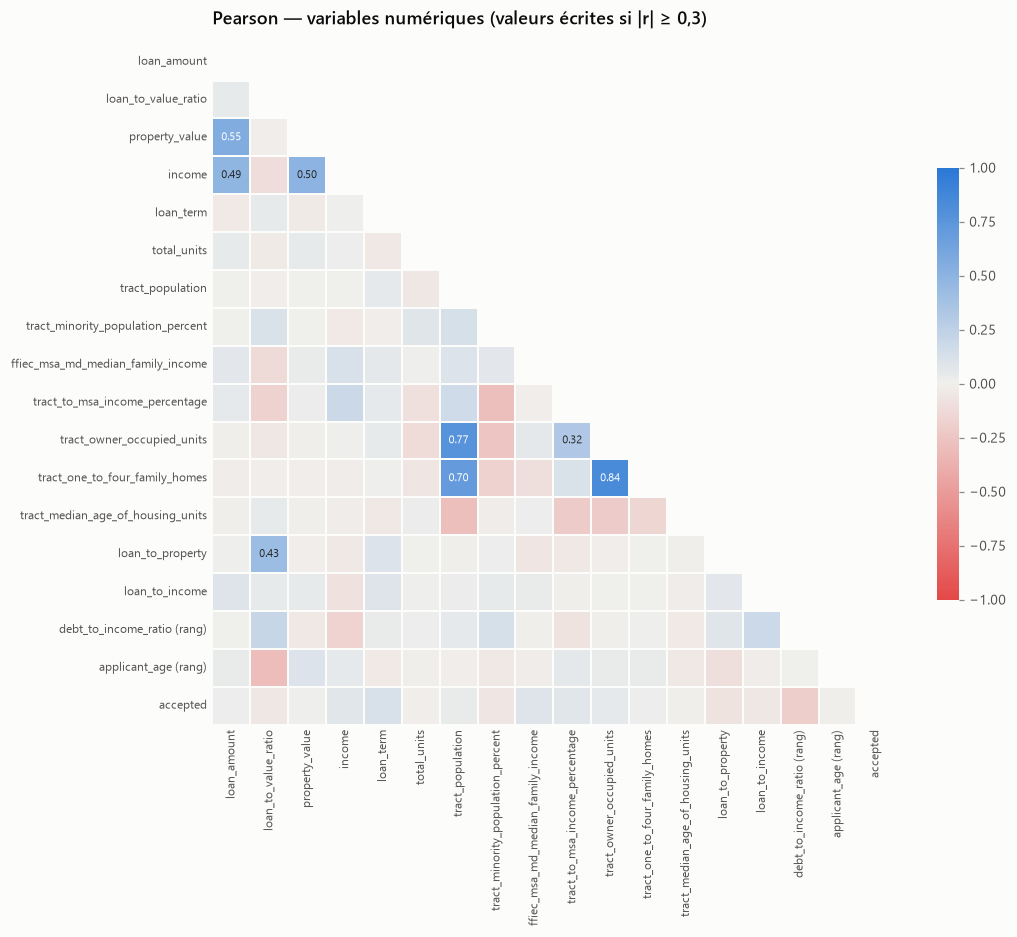

In [38]:
DIVERGING_CMAP = sns.blend_palette(["#e34948", "#f0efec", "#2a78d6"], as_cmap=True)
SEQUENTIAL_CMAP = sns.blend_palette(["#f0efec", "#86b6ef", "#2a78d6", "#0d366b"], as_cmap=True)

# Données nettoyées selon les décisions des étapes 3 et 4
data6 = clean_tract(fix_ltv_fraction(train)[0])
data6 = data6[~((data6["loan_to_value_ratio"] > 1000) | (data6["income"] == 71000))].copy()
data6["loan_to_property"] = data6["loan_amount"] / data6["property_value"] * 100
data6["loan_to_income"] = data6["loan_amount"] / (data6["income"].where(data6["income"] > 0) * 1000)

# Variables en tranches ordonnées : codées par leur rang pour entrer dans les corrélations
data6["debt_to_income_ratio (rang)"] = data6["debt_to_income_ratio"].map({v: i for i, v in enumerate(DTI_ORDER)})
data6["applicant_age (rang)"] = data6["applicant_age"].map({v: i for i, v in enumerate(AGE_ORDER)})

NUM6 = NUM_COLS + ["loan_to_property", "loan_to_income", "debt_to_income_ratio (rang)", "applicant_age (rang)", TARGET]
pearson = data6[NUM6].corr(method="pearson")
spearman = data6[NUM6].corr(method="spearman")
print(f"{len(data6):,} dossiers, {len(NUM6)} variables (dont la cible, en dernière ligne)")


def plot_matrix(mat, title, cmap, vmin, annot_min, figsize):
    """Matrice en triangle inférieur ; seules les valeurs fortes sont écrites dans les cases."""
    mask = np.triu(np.ones_like(mat, dtype=bool))
    annot = mat.apply(lambda col: col.map("{:.2f}".format)).where(mat.abs() >= annot_min, "")
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(mat, mask=mask, cmap=cmap, vmin=vmin, vmax=1, annot=annot, fmt="", annot_kws={"fontsize": 7},
                linewidths=1, linecolor=SURFACE, square=True, ax=ax, cbar_kws={"shrink": 0.6})
    ax.set_title(title)
    ax.grid(False)
    ax.tick_params(length=0, labelsize=8)
    plt.show()


plot_matrix(pearson, "Pearson — variables numériques (valeurs écrites si |r| ≥ 0,3)", DIVERGING_CMAP, -1, 0.3, (10, 8.5))

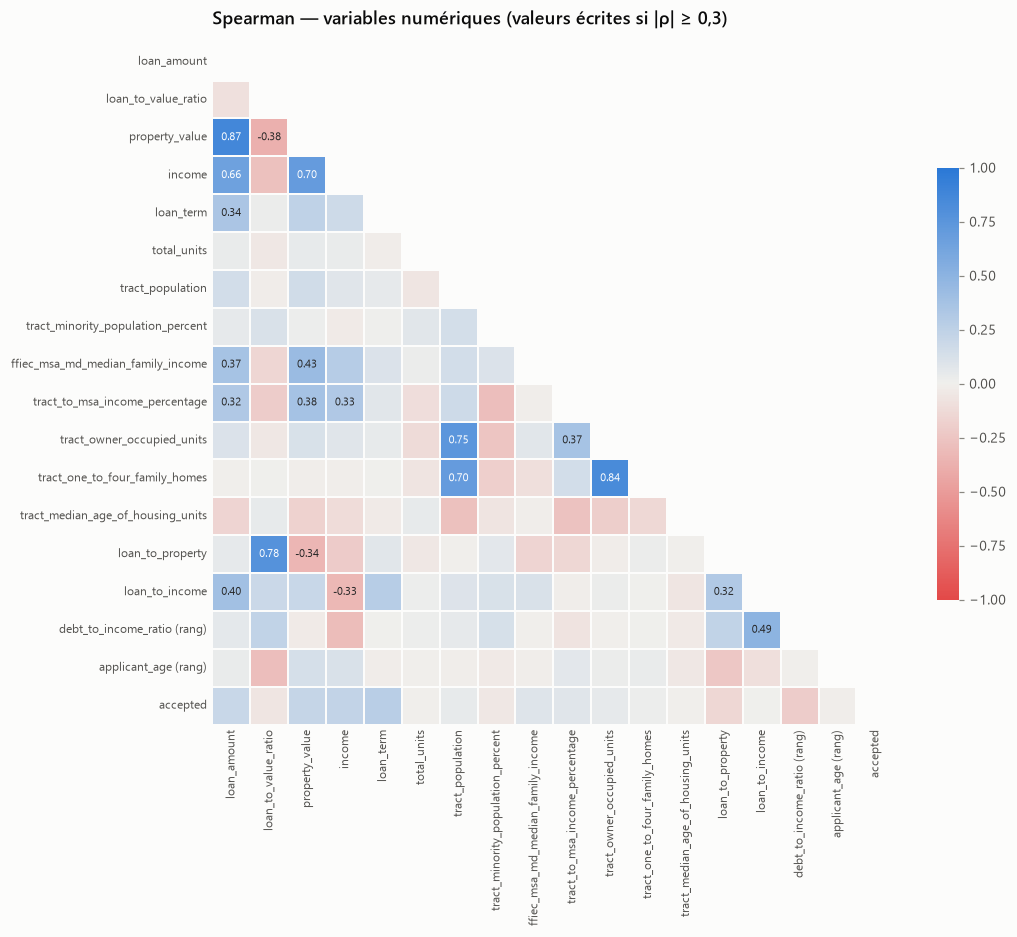

In [39]:
plot_matrix(spearman, "Spearman — variables numériques (valeurs écrites si |ρ| ≥ 0,3)", DIVERGING_CMAP, -1, 0.3, (10, 8.5))

In [40]:
# Là où Pearson et Spearman divergent le plus : signe de valeurs extrêmes ou d'une relation non linéaire
gap = (spearman - pearson).where(~np.triu(np.ones_like(pearson, dtype=bool)))
gap_pairs = gap.stack().rename("Spearman - Pearson").to_frame()
gap_pairs["Pearson"] = pearson.where(~np.triu(np.ones_like(pearson, dtype=bool))).stack()
gap_pairs["Spearman"] = spearman.where(~np.triu(np.ones_like(spearman, dtype=bool))).stack()
gap_pairs.reindex(gap_pairs["Spearman - Pearson"].abs().sort_values(ascending=False).index).head(8)

,,Spearman - Pearson,Pearson,Spearman
ffiec_msa_md_median_family_income,property_value,0.40,0.03,0.43
loan_term,loan_amount,0.38,-0.03,0.34
property_value,loan_to_value_ratio,-0.37,-0.01,-0.38
loan_to_property,loan_to_value_ratio,0.35,0.43,0.78
tract_to_msa_income_percentage,property_value,0.35,0.03,0.38
loan_to_property,property_value,-0.32,-0.01,-0.34
property_value,loan_amount,0.31,0.55,0.87
ffiec_msa_md_median_family_income,loan_amount,0.31,0.06,0.37


### 6.2 Variables catégorielles : prêt, bien et instruction du dossier

Les V de Cramér sont calculés **sans les dossiers Exempt** (3 016 lignes). Ces dossiers ont `1111` dans les 14 mêmes colonnes à la fois (étape 3) : cela suffit à créer un V d'environ 0,7 entre toutes ces colonnes, même quand elles ne disent rien d'autre de commun. Ce lien est déjà connu ; on le retire pour voir les vraies redondances.

101,981 dossiers non Exempt


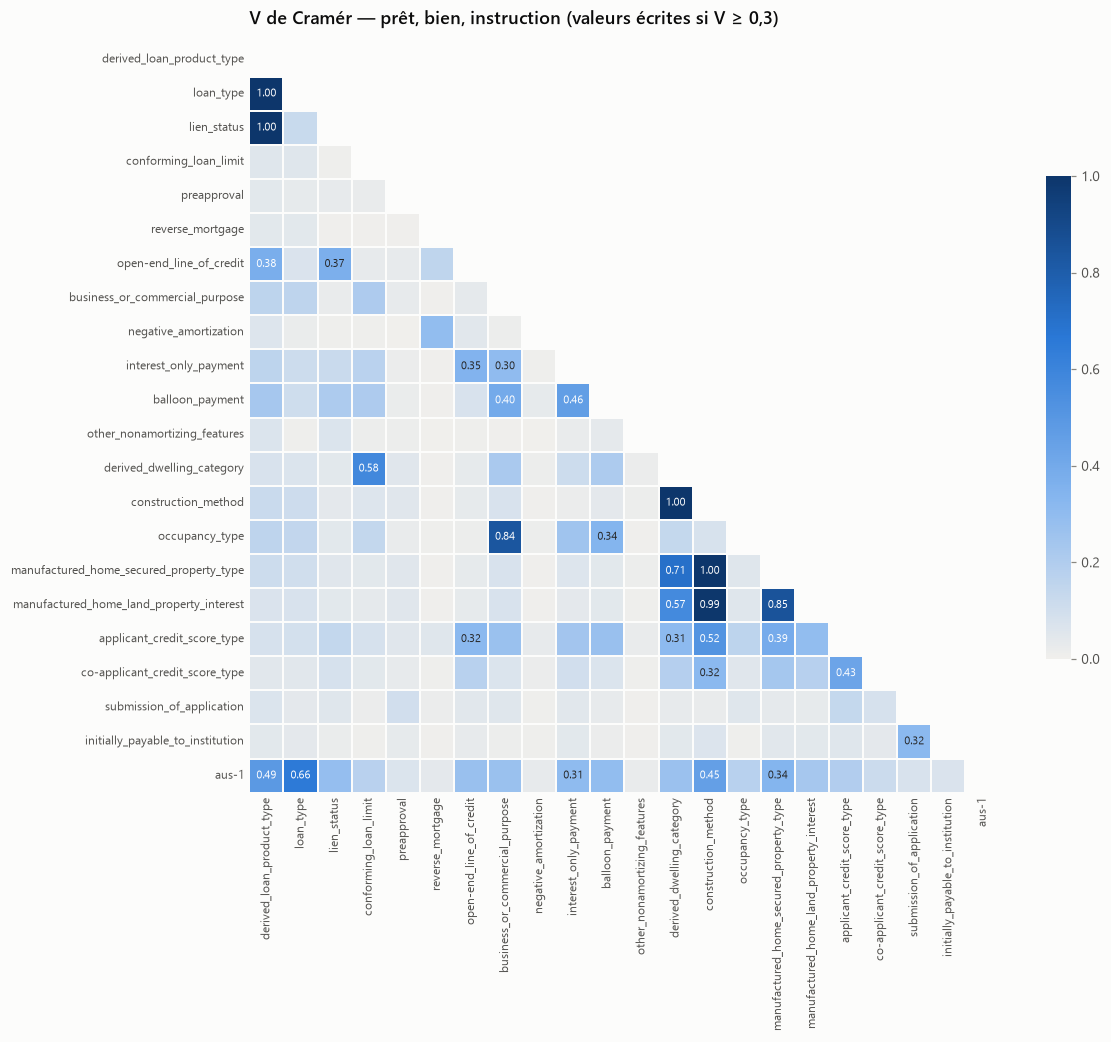

In [41]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))


def cramers_matrix(df, cols):
    """V de Cramér pour toutes les paires de colonnes (NaN traité comme une modalité)."""
    cats = {col: as_category(df[col]) for col in cols}
    mat = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    for i, a in enumerate(cols):
        for b in cols[:i]:
            mat.loc[a, b] = mat.loc[b, a] = cramers_v(cats[a], cats[b])
    return mat


# Dossiers non Exempt seulement (voir le texte au-dessus)
data_cat = data6[(data6[EXEMPT_COLS] != 1111).all(axis=1)]
print(f"{len(data_cat):,} dossiers non Exempt")

BLOCK_LOAN = VAR_GROUPS["cat_pret"] + VAR_GROUPS["cat_bien"] + VAR_GROUPS["cat_instruction"]
v_loan = cramers_matrix(data_cat, BLOCK_LOAN)
plot_matrix(v_loan, "V de Cramér — prêt, bien, instruction (valeurs écrites si V ≥ 0,3)", SEQUENTIAL_CMAP, 0, 0.3, (11, 9.5))

### 6.3 Variables catégorielles : profil de l'emprunteur et du co-emprunteur

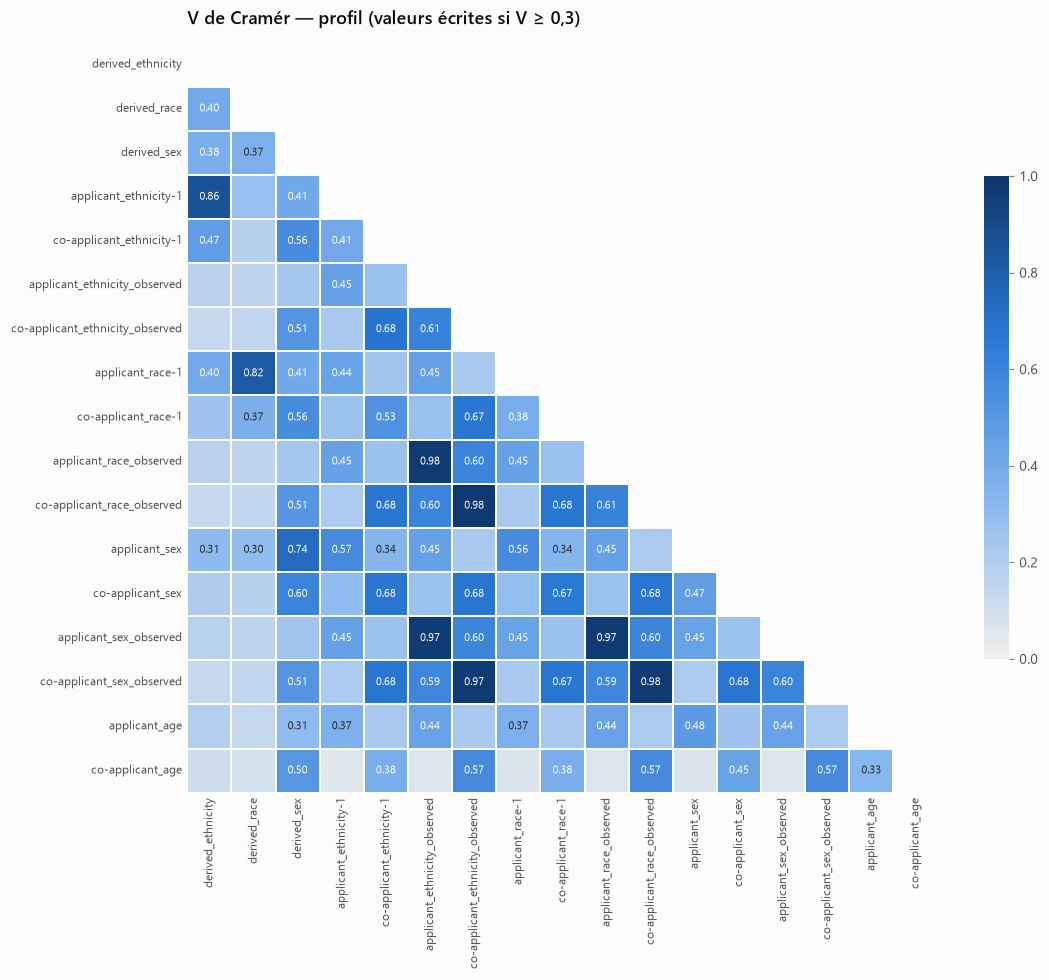

In [42]:
BLOCK_PROFILE = VAR_GROUPS["cat_profil"] + ["applicant_age", "co-applicant_age"]
v_profile = cramers_matrix(data_cat, BLOCK_PROFILE)
plot_matrix(v_profile, "V de Cramér — profil (valeurs écrites si V ≥ 0,3)", SEQUENTIAL_CMAP, 0, 0.3, (11, 9.5))

### 6.4 Variables géographiques

In [43]:
v_geo = cramers_matrix(data_cat, VAR_GROUPS["geo"])
v_geo

,state_code,derived_msa-md,county_code
state_code,1.00,0.83,0.99
derived_msa-md,0.83,1.00,1.00
county_code,0.99,1.00,1.00


### 6.5 Paires les plus corrélées

Toutes les paires au-dessus de 0,7 (en valeur absolue), toutes mesures confondues, hors cible.

In [44]:
def strong_pairs(mat, measure, threshold=0.7):
    lower = mat.where(~np.triu(np.ones_like(mat, dtype=bool)))
    pairs = lower.stack().rename("valeur").reset_index()
    pairs.columns = ["variable 1", "variable 2", "valeur"]
    pairs = pairs[(pairs["valeur"].abs() >= threshold) & (pairs["variable 1"] != TARGET) & (pairs["variable 2"] != TARGET)]
    return pairs.assign(mesure=measure)


top_pairs = pd.concat([
    strong_pairs(pearson, "Pearson"),
    strong_pairs(spearman, "Spearman"),
    strong_pairs(v_loan, "V de Cramér"),
    strong_pairs(v_profile, "V de Cramér"),
    strong_pairs(v_geo, "V de Cramér"),
]).sort_values("valeur", key=abs, ascending=False)
with pd.option_context("display.max_rows", None):
    display(top_pairs.set_index(["variable 1", "variable 2"]))

,,valeur,mesure
variable 1,variable 2,,
loan_type,derived_loan_product_type,1.00,V de Cramér
construction_method,derived_dwelling_category,1.00,V de Cramér
lien_status,derived_loan_product_type,1.00,V de Cramér
county_code,derived_msa-md,1.00,V de Cramér
manufactured_home_secured_property_type,construction_method,1.00,V de Cramér
county_code,state_code,0.99,V de Cramér
manufactured_home_land_property_interest,construction_method,0.99,V de Cramér
co-applicant_race_observed,co-applicant_ethnicity_observed,0.98,V de Cramér
co-applicant_sex_observed,co-applicant_race_observed,0.98,V de Cramér


### 6.6 À retenir

**Pearson ou Spearman ?** Sur ces données, Spearman est plus fiable. Pearson est écrasé par les valeurs extrêmes : `loan_amount` et `property_value` ont un Pearson de 0,55 mais un Spearman de 0,87. Les seuils ci-dessous se lisent avec Spearman pour les numériques.

**Groupes de variables redondantes (au-dessus de 0,7)**

| Groupe | Liens | Proposition |
|---|---|---|
| Type de produit | `derived_loan_product_type` = `loan_type` × `lien_status` (V = 1,00) | supprimer `derived_loan_product_type` |
| Maison préfabriquée | `construction_method` ↔ `derived_dwelling_category` (1,00), ↔ `manufactured_home_secured_property_type` (1,00), ↔ `manufactured_home_land_property_interest` (0,99) | garder `derived_dwelling_category` (qui contient aussi « multifamilial »), supprimer `construction_method` ; les deux `manufactured_home_*` n'ajoutent un détail que pour les 9 544 maisons préfabriquées : à garder ou supprimer |
| Mode de collecte du profil | les 3 `applicant_*_observed` entre eux (0,97 à 0,98), idem pour le co-emprunteur | n'en garder qu'un par personne |
| Profil dérivé / brut | `derived_ethnicity` ↔ `applicant_ethnicity-1` (0,86), `derived_race` ↔ `applicant_race-1` (0,82), `derived_sex` ↔ `applicant_sex` (0,74) | garder l'une des deux versions pour chaque critère (dépend aussi de la décision de garder ou non les variables de profil) |
| Géographie | `county_code` détermine `derived_msa-md` (1,00) et `state_code` (0,99) ; MSA ↔ État (0,83) | les comtés sont emboîtés dans les MSA et les États : garder les comtés, ou garder MSA + État |
| Usage du bien | `occupancy_type` ↔ `business_or_commercial_purpose` (0,84) | à décider : un bien d'investissement va souvent avec un prêt à but commercial |
| Montants | `loan_amount` ↔ `property_value` (0,87), `property_value` ↔ `income` (0,70) | garder : ce sont des variables centrales, le lasso arbitrera |
| Ratios | `loan_to_property` ↔ `loan_to_value_ratio` (0,78) | garder les deux, comme décidé à l'étape 4 (le lasso arbitrera) |
| Quartier | `tract_owner_occupied_units` ↔ `tract_one_to_four_family_homes` (0,84), ↔ `tract_population` (0,75) ; `tract_population` ↔ `tract_one_to_four_family_homes` (0,70) | trois mesures de la taille du quartier : en garder une ou deux |

**Lien avec la cible.** Aucune variable numérique n'est fortement corrélée à `accepted` (toutes sous 0,3 en valeur absolue). Ce n'est pas surprenant : les étapes 4 et 5 ont montré des effets de seuil (taux d'endettement au-delà de 60 %, revenus très faibles) que la corrélation, qui mesure une tendance globale, capte mal.

### 6.7 Variables à retirer : deux listes

On ne supprime rien des données maintenant. On range les variables dans deux listes, qui serviront à l'étape 8 et à la modélisation :
- **`DROP_SURE`** : redondance totale, retirées dans tous les modèles ;
- **`DROP_MAYBE`** : retrait possible, à tester en comparant les modèles avec et sans.

Les variables de profil servent aussi à construire `has_coapplicant` et `applicant_not_person` (étape 3) : ces deux variables sont calculées avant tout retrait.

In [45]:
DROP_SURE = [
    # = loan_type x lien_status (V de Cramér = 1,00)
    "derived_loan_product_type",
    # entièrement déterminée par derived_dwelling_category (V = 1,00)
    "construction_method",
    # mode de collecte du profil : les 3 *_observed d'une même personne sont quasi identiques (V >= 0,97),
    # on garde *_ethnicity_observed
    "applicant_race_observed", "applicant_sex_observed",
    "co-applicant_race_observed", "co-applicant_sex_observed",
]

DROP_MAYBE = [
    # Profil : race, ethnie et sexe (question légale et éthique, voir étape 5)
    "derived_race", "applicant_race-1", "co-applicant_race-1",
    "derived_ethnicity", "applicant_ethnicity-1", "co-applicant_ethnicity-1",
    "derived_sex", "applicant_sex", "co-applicant_sex",
    # Détail des maisons préfabriquées, très lié à derived_dwelling_category (V = 0,71 et 0,57)
    "manufactured_home_secured_property_type", "manufactured_home_land_property_interest",
    # Comté : emboîté dans la MSA et l'État (V = 1,00 et 0,99) ; on garde MSA + État
    "county_code",
    # Très lié à occupancy_type (V = 0,84)
    "business_or_commercial_purpose",
    # Taille du quartier : la plus corrélée aux deux autres (0,84 et 0,75)
    "tract_owner_occupied_units",
]

assert not set(DROP_SURE) & set(DROP_MAYBE)
assert set(DROP_SURE + DROP_MAYBE) <= set(features)
print(f"Variables explicatives au départ        : {len(features)}")
print(f"Après retrait de DROP_SURE              : {len(features) - len(DROP_SURE)}")
print(f"Après retrait de DROP_SURE + DROP_MAYBE : {len(features) - len(DROP_SURE) - len(DROP_MAYBE)}")

Variables explicatives au départ        : 56
Après retrait de DROP_SURE              : 50
Après retrait de DROP_SURE + DROP_MAYBE : 36


## 8. Pipeline de preprocessing

L'étape 7 (comparaison train / test) n'a pas été faite à part : à chaque étape, les taux de NaN, les codes spéciaux et les modalités du test étaient quasi identiques à ceux du train.

Le code du preprocessing est dans `src/housing_loan_prediction/preprocessing.py`, pour être réutilisé tel quel dans les notebooks de modélisation. Il se fait en deux temps :

1. **`clean(df, rare_msa, frequent_counties, is_train)`** : toutes les corrections et recodages décidés aux étapes 3 à 6, ligne à ligne. Rien n'y est appris à partir de la cible, donc on l'applique une fois au train et au test.
2. **`build_linear_preprocessor(df, drop)`** : les transformations qui s'apprennent sur les données d'entraînement (médianes, bornes, moyennes et écarts-types, liste des modalités). Elles doivent être réapprises dans chaque pli de validation croisée, donc ce préprocesseur se place dans un `Pipeline` avec le modèle.

On n'exporte pas de fichier « propre » : relancer `clean` sur les données brutes prend quelques secondes, et un CSV ferait perdre les types (les codes redeviendraient des nombres).

### 8.1 Nettoyage

In [46]:
from housing_loan_prediction.preprocessing import (
    DROP_MAYBE, DROP_SURE, FLAG_COLS, NUM_COLS, build_linear_preprocessor, categorical_columns, clean,
    find_frequent_counties,
    find_rare_msa,
)

rare_msa, frequent_counties = find_rare_msa(train), find_frequent_counties(train)
train_clean = clean(train, rare_msa, frequent_counties, is_train=True)
test_clean = clean(test, rare_msa, frequent_counties)

cat_cols = categorical_columns(train_clean)
print(f"train : {train.shape} -> {train_clean.shape} ({len(train) - len(train_clean)} dossiers aberrants retirés)")
print(f"test  : {test.shape} -> {test_clean.shape}")
print(f"{len(NUM_COLS)} numériques, {len(FLAG_COLS)} indicateurs 0/1, {len(cat_cols)} catégorielles")
print(f"NaN restants dans les catégorielles : {train_clean[cat_cols].isna().sum().sum()} (train), "
      f"{test_clean[cat_cols].isna().sum().sum()} (test)")

# Les seuls NaN restants sont des NaN purs dans les numériques, traités par le pipeline
pd.DataFrame({
    "NaN train": train_clean[NUM_COLS].isna().sum(),
    "NaN test": test_clean[NUM_COLS].isna().sum(),
}).query("`NaN train` > 0 or `NaN test` > 0")

train : (105000, 58) -> (104996, 67) (4 dossiers aberrants retirés)
test  : (45000, 57) -> (45000, 66)
15 numériques, 7 indicateurs 0/1, 43 catégorielles
NaN restants dans les catégorielles : 0 (train), 0 (test)


,NaN train,NaN test
loan_to_value_ratio,11873,5079
property_value,4754,1988
income,4578,2022
loan_term,3305,1397
tract_population,2117,929
tract_minority_population_percent,2117,929
ffiec_msa_md_median_family_income,2117,929
tract_to_msa_income_percentage,2117,929
tract_owner_occupied_units,2117,929
tract_one_to_four_family_homes,2117,929


In [47]:
# Contrôle de quelques recodages
display(pd.DataFrame({
    "co-applicant_age": train_clean["co-applicant_age"].value_counts(),
    "applicant_age": train_clean["applicant_age"].value_counts(),
}).fillna(0).astype(int))
display(train_clean[FLAG_COLS].mean().mul(100).rename("% de dossiers à 1").to_frame())

,co-applicant_age,applicant_age
25-34,14076,30933
35-44,11285,27055
45-54,7380,17437
55-64,6102,11990
65-74,3384,5903
<25,2962,6762
>74,1118,1828
Manquant,107,179
Pas de co-emprunteur,57575,0
Sans objet,1007,2909


,% de dossiers à 1
has_coapplicant,45.16
applicant_not_person,2.77
ltv_missing,11.31
property_value_missing,4.53
income_missing,5.27
loan_term_missing,3.15
tract_unknown,2.02


### 8.2 Transformations pour les modèles linéaires

Deux versions selon les variables retirées : `DROP_SURE` seule, ou `DROP_SURE` + `DROP_MAYBE`. Le préprocesseur est ajusté ici sur tout le train seulement pour vérifier le résultat.

In [48]:
for name, drop in [("DROP_SURE", DROP_SURE), ("DROP_SURE + DROP_MAYBE", DROP_SURE + DROP_MAYBE)]:
    prep = build_linear_preprocessor(train_clean, drop)
    X_train = prep.fit_transform(train_clean)
    X_test = prep.transform(test_clean)
    blocks = pd.Series(prep.get_feature_names_out()).str.split("__").str[0].value_counts()
    print(f"{name} : {X_train.shape[1]:,} colonnes ({blocks.to_dict()}), "
          f"NaN train = {np.isnan(X_train.data).sum()}, NaN test = {np.isnan(X_test.data).sum()}")

# Les numériques transformées sont bien centrées-réduites (dernière version ajustée)
n_num = blocks["log"] + blocks["num"]
X_num = X_train[:, :n_num].toarray()
pd.DataFrame({"moyenne": X_num.mean(axis=0), "écart-type": X_num.std(axis=0)},
             index=prep.get_feature_names_out()[:n_num]).round(3)

DROP_SURE : 3,567 colonnes ({'cat': 3545, 'num': 10, 'flag': 7, 'log': 5}), NaN train = 0, NaN test = 0


DROP_SURE + DROP_MAYBE : 583 colonnes ({'cat': 562, 'num': 9, 'flag': 7, 'log': 5}), NaN train = 0, NaN test = 0


,moyenne,écart-type
log__loan_amount,-0.00,1.00
log__property_value,0.00,1.00
log__income,0.00,1.00
log__loan_to_property,-0.00,1.00
log__loan_to_income,-0.00,1.00
num__loan_to_value_ratio,-0.00,1.00
num__loan_term,-0.00,1.00
num__total_units,0.00,1.00
num__tract_population,-0.00,1.00
num__tract_minority_population_percent,-0.00,1.00


### 8.3 Utilisation dans un notebook de modélisation

```python
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

from housing_loan_prediction.preprocessing import DROP_MAYBE, DROP_SURE, build_linear_preprocessor, clean, find_frequent_counties, find_rare_msa

rare_msa, frequent_counties = find_rare_msa(train), find_frequent_counties(train)
train_clean = clean(train, rare_msa, frequent_counties, is_train=True)
test_clean = clean(test, rare_msa, frequent_counties)

model = make_pipeline(
    build_linear_preprocessor(train_clean, drop=DROP_SURE),  # ou DROP_SURE + DROP_MAYBE
    LogisticRegression(max_iter=2000),
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, train_clean, train_clean["accepted"], cv=cv, scoring="roc_auc")
```

Pour un lasso : `LogisticRegression(penalty="l1", solver="saga", C=...)`, `C` étant l'inverse de la force de pénalité.

### 8.4 À retenir : ce que fait le pipeline

**`clean`** (train et test)
- Retire 4 dossiers aberrants du train (LTV > 1000, revenu de 71 M$).
- Crée `has_coapplicant` et `applicant_not_person`, avant tout recodage du profil.
- Corrige les LTV saisis en fraction quand le ratio recalculé le confirme.
- Passe en NaN les variables de quartier quand le quartier est inconnu.
- Manquants structurels : `total_units` → 5, `conforming_loan_limit` → « NA », âges → « Pas de co-emprunteur » ou « Sans objet ».
- Regroupements de modalités rares de l'étape 5 (types de score, race, ethnie, territoires hors États, petites MSA vers 99999).
- Ajoute `loan_to_property`, `loan_to_income` et les 5 indicateurs de manquant.
- Les catégorielles deviennent du texte ; un NaN restant devient « Manquant ».

**`build_linear_preprocessor`** (appris sur le train, ou sur chaque pli)
- Numériques : NaN → médiane, log des montants asymétriques, bornage aux quantiles 0,1 % et 99,9 %, centrage-réduction.
- Indicateurs 0/1 : inchangés.
- Catégorielles : one-hot ; une modalité du test absente du train donne une ligne de zéros.
- Retire les variables de `DROP_SURE`, et de `DROP_MAYBE` si demandé.